In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("Historical Product Demand.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:

print("Dataset Shape:", df.shape)


Dataset Shape: (1048575, 5)


In [4]:

df.head(10)


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
0,Product_0993,Whse_J,Category_028,2012/7/27,100
1,Product_0979,Whse_J,Category_028,2012/1/19,500
2,Product_0979,Whse_J,Category_028,2012/2/3,500
3,Product_0979,Whse_J,Category_028,2012/2/9,500
4,Product_0979,Whse_J,Category_028,2012/3/2,500
5,Product_0979,Whse_J,Category_028,2012/4/19,500
6,Product_0979,Whse_J,Category_028,2012/6/5,500
7,Product_0979,Whse_J,Category_028,2012/6/27,500
8,Product_0979,Whse_J,Category_028,2012/7/23,500
9,Product_0979,Whse_J,Category_028,2012/8/29,500


In [5]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype 
---  ------            --------------    ----- 
 0   Product_Code      1048575 non-null  object
 1   Warehouse         1048575 non-null  object
 2   Product_Category  1048575 non-null  object
 3   Date              1037336 non-null  object
 4   Order_Demand      1048575 non-null  object
dtypes: object(5)
memory usage: 40.0+ MB


In [6]:

# Check missing values in each column

missing_values = df.isnull().sum()

print(missing_values)


Product_Code            0
Warehouse               0
Product_Category        0
Date                11239
Order_Demand            0
dtype: int64


In [7]:

# Display records where Date is missing

df[df['Date'].isnull()].head(10)


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
45460,Product_1461,Whse_A,Category_019,NaN,10000
456373,Product_1636,Whse_A,Category_019,NaN,100
456374,Product_1461,Whse_A,Category_019,NaN,300
456375,Product_1464,Whse_A,Category_019,NaN,300
456376,Product_1388,Whse_A,Category_019,NaN,200
456377,Product_1464,Whse_A,Category_019,NaN,600
456378,Product_1402,Whse_A,Category_019,NaN,600
456379,Product_1461,Whse_A,Category_019,NaN,100
456380,Product_1539,Whse_A,Category_019,NaN,100
456381,Product_1388,Whse_A,Category_019,NaN,800


In [8]:

# Check missing dates by warehouse

df[df['Date'].isnull()]['Warehouse'].value_counts()


Warehouse
Whse_A    11239
Name: count, dtype: int64

In [9]:
df[df['Date'].isnull()]['Product_Category'].value_counts()

Product_Category
Category_019    10833
Category_028      290
Category_005       44
Category_026       32
Category_006       25
Category_031       12
Category_021        3
Name: count, dtype: int64

In [10]:
# Find the row positions of missing dates

missing_date_index = df[df['Date'].isnull()].index

print("First missing date row:", missing_date_index.min())
print("Last missing date row:", missing_date_index.max())
print("Total missing date rows:", len(missing_date_index))

First missing date row: 45460
Last missing date row: 995794
Total missing date rows: 11239


In [11]:
# Count duplicate rows

print("Total duplicate records:", df.duplicated().sum())

Total duplicate records: 122423


In [12]:
# Display the most frequently repeated records

duplicate_records = df[df.duplicated(keep=False)]

duplicate_records.value_counts().head(10)

Product_Code  Warehouse  Product_Category  Date        Order_Demand
Product_1496  Whse_A     Category_019      2013/10/25  0               42
                                           2013/9/27   0               41
                                           2013/10/30  0               40
                                           2013/10/26  0               39
                                           2013/10/28  0               39
Product_1424  Whse_A     Category_019      2013/10/25  0               31
                                           2013/9/27   0               31
                                           2013/10/30  0               31
                                           2013/10/28  0               31
                                           2013/10/26  0               31
Name: count, dtype: int64

In [13]:
# Display unique demand values (first 30)

df['Order_Demand'].unique()[:30]

array(['100 ', '500 ', '50000 ', '100000 ', '4 ', '150000 ', '160000 ',
       '1000 ', '20000 ', '2000 ', '10000 ', '30000 ', '40000 ', '60000 ',
       '28000 ', '4000 ', '9000 ', '23000 ', '26000 ', '35000 ', '36000 ',
       '15000 ', '7000 ', '42000 ', '45000 ', '16000 ', '3000 ', '600 ',
       '300 ', '1600 '], dtype=object)

In [14]:

# Inspect demand values containing brackets or minus signs

special_values = df[
    df['Order_Demand'].str.contains(r'[()-]', na=False)
]['Order_Demand'].value_counts()

print("Number of special demand values:", len(special_values))
print(special_values.head(20))


Number of special demand values: 540
Order_Demand
(100)     1199
(200)      902
(1000)     591
(1)        542
(300)      494
(500)      438
(400)      373
(2)        367
(50)       295
(10)       259
(2000)     238
(600)      194
(4)        177
(5)        164
(3)        154
(20)       141
(25)       133
(700)      132
(6)        106
(1500)     102
Name: count, dtype: int64


In [15]:

# Count demand values represented using parentheses

negative_mask = df['Order_Demand'].str.contains(
    r'^\s*\(.*\)\s*$', na=False
)

print("Total negative demand records:", negative_mask.sum())

print("\nSample negative demand values:")
print(df.loc[negative_mask, 'Order_Demand'].value_counts().head(15))


Total negative demand records: 10469

Sample negative demand values:
Order_Demand
(100)     1199
(200)      902
(1000)     591
(1)        542
(300)      494
(500)      438
(400)      373
(2)        367
(50)       295
(10)       259
(2000)     238
(600)      194
(4)        177
(5)        164
(3)        154
Name: count, dtype: int64


In [16]:

# Count zero-demand records

zero_demand = (
    df['Order_Demand'].str.strip() == '0'
)

print("Total zero-demand records:", zero_demand.sum())

print("\nPercentage of zero-demand records:",
      round(zero_demand.mean() * 100, 2), "%")


Total zero-demand records: 28681

Percentage of zero-demand records: 2.74 %


In [17]:

# Identify demand values that are not standard numbers
# or accounting-style negative numbers

clean_format = df['Order_Demand'].str.strip()

valid_demand = clean_format.str.match(
    r'^(\d+|\(\d+\))$',
    na=False
)

print("Valid demand records:", valid_demand.sum())
print("Unusual demand records:", (~valid_demand).sum())

print("\nUnusual demand examples:")
print(df.loc[~valid_demand, 'Order_Demand'].value_counts().head(20))


Valid demand records: 1048575
Unusual demand records: 0

Unusual demand examples:
Series([], Name: count, dtype: int64)


In [18]:
# Create a copy of the original dataset

df_clean = df.copy()

print("Working copy created successfully!")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Working copy created successfully!
Original dataset shape: (1048575, 5)
Working dataset shape: (1048575, 5)


In [19]:

# Remove leading and trailing whitespace from text columns

for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

print("Whitespace cleaning completed!")

# Verify Order_Demand
print(df_clean['Order_Demand'].head(10).tolist())


Whitespace cleaning completed!
['100', '500', '500', '500', '500', '500', '500', '500', '500', '500']


In [20]:

# Convert Date column into datetime format

df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    errors='coerce'
)

print("Date conversion completed!")

print("\nDate data type:")
print(df_clean['Date'].dtype)

print("\nSample dates:")
print(df_clean['Date'].head(10))


Date conversion completed!

Date data type:
datetime64[ns]

Sample dates:
0   2012-07-27
1   2012-01-19
2   2012-02-03
3   2012-02-09
4   2012-03-02
5   2012-04-19
6   2012-06-05
7   2012-06-27
8   2012-07-23
9   2012-08-29
Name: Date, dtype: datetime64[ns]


In [21]:

# Convert accounting-style negative values into standard negatives

df_clean['Order_Demand'] = (
    df_clean['Order_Demand']
    .str.replace(r'^\((\d+)\)$', r'-\1', regex=True)
    .astype('int64')
)

print("Demand conversion completed!")

print("\nData type:")
print(df_clean['Order_Demand'].dtype)

print("\nSample demand values:")
print(df_clean['Order_Demand'].head(10).tolist())

print("\nNegative demand examples:")
print(df_clean.loc[df_clean['Order_Demand'] < 0, 'Order_Demand'].head())


Demand conversion completed!

Data type:
int64

Sample demand values:
[100, 500, 500, 500, 500, 500, 500, 500, 500, 500]

Negative demand examples:
112290     -1
112307    -24
112308    -24
112356    -50
112357   -100
Name: Order_Demand, dtype: int64


In [22]:

print("Updated Dataset Information:")
df_clean.info()


Updated Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   Product_Code      1048575 non-null  object        
 1   Warehouse         1048575 non-null  object        
 2   Product_Category  1048575 non-null  object        
 3   Date              1037336 non-null  datetime64[ns]
 4   Order_Demand      1048575 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 40.0+ MB


In [23]:

# Analyse demand values in records with missing dates

missing_date_data = df_clean[df_clean['Date'].isnull()]

print("Total records:", len(missing_date_data))

print("\nDemand summary:")
print(missing_date_data['Order_Demand'].describe())

print("\nNegative demand records:",
      (missing_date_data['Order_Demand'] < 0).sum())

print("Zero demand records:",
      (missing_date_data['Order_Demand'] == 0).sum())

print("Positive demand records:",
      (missing_date_data['Order_Demand'] > 0).sum())


Total records: 11239

Demand summary:
count     11239.000000
mean          0.897767
std        6093.743933
min     -396200.000000
25%        -250.000000
50%         100.000000
75%         400.000000
max      396200.000000
Name: Order_Demand, dtype: float64

Negative demand records: 4570
Zero demand records: 9
Positive demand records: 6660


In [24]:

# Create a separate dataset containing valid dates

df_model = df_clean.dropna(subset=['Date']).copy()

print("Original cleaned dataset:", df_clean.shape)
print("Time-series modelling dataset:", df_model.shape)

print("\nMissing dates in modelling dataset:",
      df_model['Date'].isnull().sum())


Original cleaned dataset: (1048575, 5)
Time-series modelling dataset: (1037336, 5)

Missing dates in modelling dataset: 0


In [25]:

print("Earliest Date:", df_model['Date'].min())

print("Latest Date:", df_model['Date'].max())

print("Total Unique Dates:", df_model['Date'].nunique())

print("Total Products:", df_model['Product_Code'].nunique())

print("Total Warehouses:", df_model['Warehouse'].nunique())

print("Total Product Categories:",
      df_model['Product_Category'].nunique())


Earliest Date: 2011-01-08 00:00:00
Latest Date: 2017-01-09 00:00:00
Total Unique Dates: 1729
Total Products: 2160
Total Warehouses: 4
Total Product Categories: 33


In [26]:

# Count records and unique dates for each year

yearly_analysis = df_model.groupby(
    df_model['Date'].dt.year
).agg(
    Total_Records=('Date', 'count'),
    Unique_Dates=('Date', 'nunique')
)

print(yearly_analysis)


      Total_Records  Unique_Dates
Date                             
2011            640            42
2012         203635           338
2013         218298           345
2014         216404           349
2015         209661           328
2016         188645           321
2017             53             6


In [27]:

# Check monthly coverage for each year

monthly_coverage = df_model.groupby(
    df_model['Date'].dt.year
).agg(
    First_Date=('Date', 'min'),
    Last_Date=('Date', 'max'),
    Months_Available=('Date',
                      lambda x: x.dt.to_period('M').nunique())
)

print(monthly_coverage)


     First_Date  Last_Date  Months_Available
Date                                        
2011 2011-01-08 2011-12-31                 7
2012 2012-01-01 2012-12-31                12
2013 2013-01-01 2013-12-31                12
2014 2014-01-01 2014-12-31                12
2015 2015-01-01 2015-12-31                12
2016 2016-01-03 2016-12-30                12
2017 2017-01-02 2017-01-09                 1


In [28]:

# Check overall calendar date coverage

date_range = pd.date_range(
    start=df_model['Date'].min(),
    end=df_model['Date'].max(),
    freq='D'
)

available_dates = df_model['Date'].drop_duplicates()

missing_calendar_dates = date_range.difference(available_dates)

print("Expected calendar days:", len(date_range))
print("Available transaction dates:", len(available_dates))
print("Dates without transactions:", len(missing_calendar_dates))

print("\nFirst 10 dates without transactions:")
print(missing_calendar_dates[:10].tolist())


Expected calendar days: 2194
Available transaction dates: 1729
Dates without transactions: 465

First 10 dates without transactions:
[Timestamp('2011-01-09 00:00:00'), Timestamp('2011-01-10 00:00:00'), Timestamp('2011-01-11 00:00:00'), Timestamp('2011-01-12 00:00:00'), Timestamp('2011-01-13 00:00:00'), Timestamp('2011-01-14 00:00:00'), Timestamp('2011-01-15 00:00:00'), Timestamp('2011-01-16 00:00:00'), Timestamp('2011-01-17 00:00:00'), Timestamp('2011-01-18 00:00:00')]


In [29]:

# Analyse daily transaction coverage from 2012 to 2016

df_main = df_model[
    df_model['Date'].dt.year.between(2012, 2016)
].copy()

coverage = []

for year in range(2012, 2017):
    expected_days = 366 if pd.Timestamp(year, 12, 31).dayofyear == 366 else 365

    available_days = df_main[
        df_main['Date'].dt.year == year
    ]['Date'].nunique()

    coverage.append({
        'Year': year,
        'Expected_Days': expected_days,
        'Available_Days': available_days,
        'Missing_Days': expected_days - available_days
    })

coverage_df = pd.DataFrame(coverage)

print(coverage_df)


   Year  Expected_Days  Available_Days  Missing_Days
0  2012            366             338            28
1  2013            365             345            20
2  2014            365             349            16
3  2015            365             328            37
4  2016            366             321            45


In [30]:

# Monthly transaction coverage from 2012 to 2016

monthly_analysis = df_main.groupby(
    df_main['Date'].dt.to_period('M')
).agg(
    Total_Records=('Date', 'count'),
    Unique_Transaction_Days=('Date', 'nunique')
)

print(monthly_analysis.head(15))


         Total_Records  Unique_Transaction_Days
Date                                           
2012-01          15614                       29
2012-02          18123                       28
2012-03          18604                       28
2012-04          16590                       28
2012-05          17014                       29
2012-06          16911                       28
2012-07          17718                       28
2012-08          16492                       29
2012-09          15613                       25
2012-10          18515                       28
2012-11          17416                       30
2012-12          15025                       28
2013-01          16638                       30
2013-02          17119                       27
2013-03          17397                       29


In [31]:

# Calculate monthly calendar coverage

monthly_analysis['Expected_Days'] = (
    monthly_analysis.index.days_in_month
)

monthly_analysis['Missing_Days'] = (
    monthly_analysis['Expected_Days']
    - monthly_analysis['Unique_Transaction_Days']
)

monthly_analysis['Coverage_Percentage'] = (
    monthly_analysis['Unique_Transaction_Days']
    / monthly_analysis['Expected_Days'] * 100
).round(2)

print(monthly_analysis.head(15))


         Total_Records  Unique_Transaction_Days  Expected_Days  Missing_Days  \
Date                                                                           
2012-01          15614                       29             31             2   
2012-02          18123                       28             29             1   
2012-03          18604                       28             31             3   
2012-04          16590                       28             30             2   
2012-05          17014                       29             31             2   
2012-06          16911                       28             30             2   
2012-07          17718                       28             31             3   
2012-08          16492                       29             31             2   
2012-09          15613                       25             30             5   
2012-10          18515                       28             31             3   
2012-11          17416                  

In [32]:

print("Monthly Coverage Summary")

print("\nAverage coverage:",
      round(monthly_analysis['Coverage_Percentage'].mean(), 2), "%")

print("Minimum coverage:",
      round(monthly_analysis['Coverage_Percentage'].min(), 2), "%")

print("Maximum coverage:",
      round(monthly_analysis['Coverage_Percentage'].max(), 2), "%")

print("Total months:",
      len(monthly_analysis))


Monthly Coverage Summary

Average coverage: 92.03 %
Minimum coverage: 80.65 %
Maximum coverage: 100.0 %
Total months: 60


In [33]:

# Statistical analysis of demand

print("Demand Distribution Summary")
print(df_main['Order_Demand'].describe())

print("\nPositive demand records:",
      (df_main['Order_Demand'] > 0).sum())

print("Negative demand records:",
      (df_main['Order_Demand'] < 0).sum())

print("Zero demand records:",
      (df_main['Order_Demand'] == 0).sum())

print("\nDemand percentiles:")
print(df_main['Order_Demand'].quantile(
    [0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
))


Demand Distribution Summary
count    1.036643e+06
mean     4.915913e+03
std      2.902620e+04
min     -9.990000e+05
25%      1.900000e+01
50%      3.000000e+02
75%      2.000000e+03
max      4.000000e+06
Name: Order_Demand, dtype: float64

Positive demand records: 1002112
Negative demand records: 5859
Zero demand records: 28672

Demand percentiles:
0.01        0.0
0.25       19.0
0.50      300.0
0.75     2000.0
0.95    20000.0
0.99    75000.0
Name: Order_Demand, dtype: float64


In [34]:

# Display the 20 highest demand transactions

print("TOP 20 HIGHEST DEMAND RECORDS")

display(
    df_main.nlargest(20, 'Order_Demand')
)

print("\nTOP 20 LOWEST DEMAND RECORDS")

display(
    df_main.nsmallest(20, 'Order_Demand')
)


TOP 20 HIGHEST DEMAND RECORDS


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
20892,Product_1432,Whse_S,Category_019,2012-06-11,4000000
20477,Product_1248,Whse_J,Category_019,2012-07-05,3000000
72638,Product_1341,Whse_C,Category_019,2012-02-06,3000000
222266,Product_1432,Whse_S,Category_019,2013-06-14,3000000
258396,Product_1248,Whse_J,Category_019,2013-11-11,2560000
108179,Product_1248,Whse_J,Category_019,2012-11-26,2500000
659046,Product_1432,Whse_S,Category_019,2015-03-13,2500000
659050,Product_1432,Whse_S,Category_019,2015-05-19,2500000
659055,Product_1432,Whse_S,Category_019,2015-10-09,2500000
871363,Product_1432,Whse_S,Category_019,2016-07-29,2500000



TOP 20 LOWEST DEMAND RECORDS


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
585144,Product_1241,Whse_J,Category_019,2014-03-27,-999000
182061,Product_1359,Whse_J,Category_019,2012-09-13,-500000
999608,Product_1817,Whse_S,Category_006,2016-06-06,-472500
146980,Product_1295,Whse_J,Category_019,2012-03-06,-322500
568159,Product_1245,Whse_C,Category_019,2014-10-14,-300000
568158,Product_1355,Whse_C,Category_019,2014-10-10,-295000
130697,Product_0071,Whse_C,Category_019,2012-11-12,-250000
410611,Product_1461,Whse_J,Category_019,2013-09-24,-249950
1000967,Product_1157,Whse_J,Category_006,2016-06-27,-240000
999609,Product_1825,Whse_S,Category_006,2016-06-06,-225000


In [35]:

# Identify transactions with extremely large demand

extreme_demand = df_main[
    (df_main['Order_Demand'] >= 100000) |
    (df_main['Order_Demand'] <= -100000)
].copy()

print("Total extreme transactions:",
      len(extreme_demand))

print("\nProducts with extreme transactions:",
      extreme_demand['Product_Code'].nunique())

print("\nWarehouses involved:",
      extreme_demand['Warehouse'].nunique())

print("\nTop 10 products with extreme transactions:")

print(
    extreme_demand['Product_Code']
    .value_counts()
    .head(10)
)


Total extreme transactions: 8935

Products with extreme transactions: 173

Warehouses involved: 4

Top 10 products with extreme transactions:
Product_Code
Product_1359    1161
Product_1248     857
Product_1341     653
Product_1016     315
Product_0083     310
Product_1241     309
Product_1245     226
Product_1570     220
Product_1480     212
Product_1278     206
Name: count, dtype: int64


In [36]:

# Analyse Product_1359 demand

product_1359 = df_main[
    df_main['Product_Code'] == 'Product_1359'
].copy()

print("Total transactions:",
      len(product_1359))

print("\nDemand statistics:")
print(product_1359['Order_Demand'].describe())

print("\nPositive demand:",
      (product_1359['Order_Demand'] > 0).sum())

print("Negative demand:",
      (product_1359['Order_Demand'] < 0).sum())

print("Zero demand:",
      (product_1359['Order_Demand'] == 0).sum())

print("\nWarehouse distribution:")
print(product_1359['Warehouse'].value_counts())


Total transactions: 16935

Demand statistics:
count    1.693500e+04
mean     2.778919e+04
std      6.968917e+04
min     -5.000000e+05
25%      3.000000e+03
50%      1.000000e+04
75%      2.500000e+04
max      2.000000e+06
Name: Order_Demand, dtype: float64

Positive demand: 16860
Negative demand: 24
Zero demand: 51

Warehouse distribution:
Warehouse
Whse_J    16935
Name: count, dtype: int64


In [37]:

# Analyse historical date coverage of Product_1359

print("First transaction date:",
      product_1359['Date'].min())

print("Last transaction date:",
      product_1359['Date'].max())

print("Unique transaction dates:",
      product_1359['Date'].nunique())

print("Total calendar days:",
      (product_1359['Date'].max() -
       product_1359['Date'].min()).days + 1)


First transaction date: 2012-01-05 00:00:00
Last transaction date: 2016-12-28 00:00:00
Unique transaction dates: 1231
Total calendar days: 1820


In [38]:

# Aggregate Product_1359 demand by date

product_1359_daily = (
    product_1359.groupby('Date')
    .agg(
        Daily_Demand=('Order_Demand', 'sum'),
        Transaction_Count=('Order_Demand', 'count')
    )
    .reset_index()
)

print("Daily dataset shape:", product_1359_daily.shape)

print("\nFirst 10 daily records:")
display(product_1359_daily.head(10))


Daily dataset shape: (1231, 3)

First 10 daily records:


,Date,Daily_Demand,Transaction_Count
0,2012-01-05,702000,16
1,2012-01-06,676000,20
2,2012-01-10,783000,24
3,2012-01-11,200000,20
4,2012-01-12,284000,17
5,2012-01-13,532000,23
6,2012-01-16,479000,16
7,2012-01-17,435000,12
8,2012-01-18,29000,5
9,2012-01-19,477000,25


In [39]:

# Statistical summary of daily demand

print("Daily Demand Statistics:")
display(product_1359_daily['Daily_Demand'].describe())

print("\nPositive demand days:",
      (product_1359_daily['Daily_Demand'] > 0).sum())

print("Negative demand days:",
      (product_1359_daily['Daily_Demand'] < 0).sum())

print("Zero demand days:",
      (product_1359_daily['Daily_Demand'] == 0).sum())


Daily Demand Statistics:


count    1.231000e+03
mean     3.822989e+05
std      2.881548e+05
min      0.000000e+00
25%      1.910000e+05
50%      3.100000e+05
75%      4.950000e+05
max      2.257000e+06
Name: Daily_Demand, dtype: float64


Positive demand days: 1228
Negative demand days: 0
Zero demand days: 3


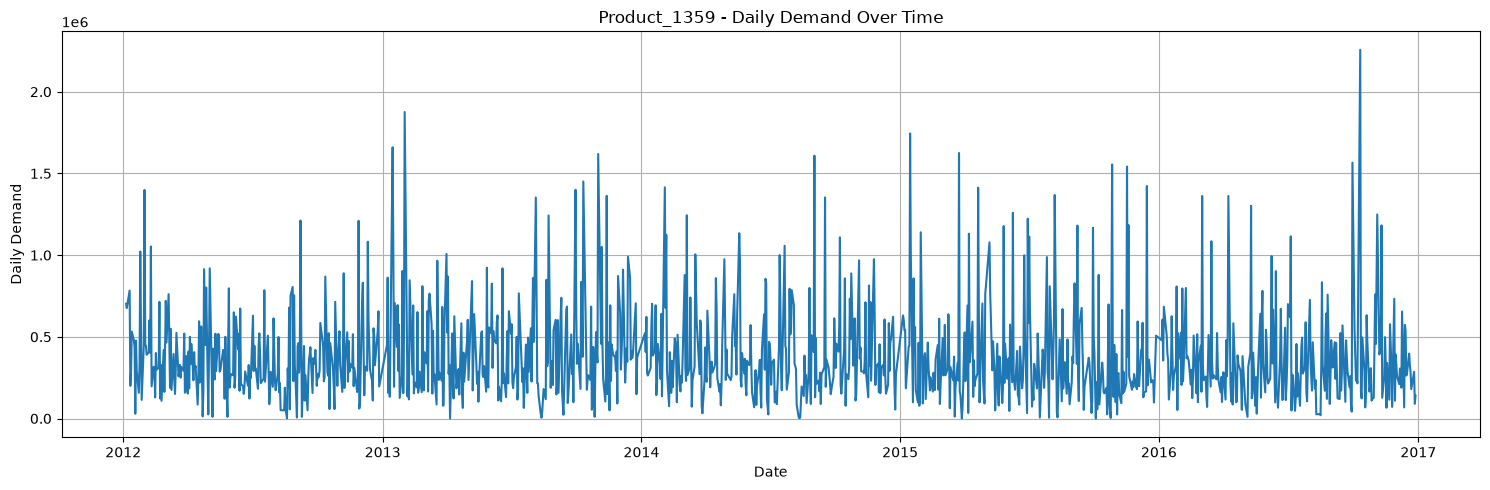

In [40]:

plt.figure(figsize=(15, 5))

plt.plot(
    product_1359_daily['Date'],
    product_1359_daily['Daily_Demand']
)

plt.title('Product_1359 - Daily Demand Over Time')
plt.xlabel('Date')
plt.ylabel('Daily Demand')
plt.grid(True)
plt.tight_layout()
plt.show()


In [41]:

# Calculate the gap between consecutive transaction dates

product_1359_daily['Days_Between_Transactions'] = (
    product_1359_daily['Date'].diff().dt.days
)

print("Gap between consecutive transaction dates:")
display(
    product_1359_daily['Days_Between_Transactions']
    .value_counts()
    .sort_index()
    .head(15)
)

print("\nAverage gap:",
      product_1359_daily['Days_Between_Transactions'].mean(), "days")

print("Maximum gap:",
      product_1359_daily['Days_Between_Transactions'].max(), "days")


Gap between consecutive transaction dates:


Days_Between_Transactions
1.0     956
2.0      33
3.0     199
4.0      32
5.0       4
6.0       2
8.0       1
10.0      1
11.0      2
Name: count, dtype: int64


Average gap: 1.478861788617886 days
Maximum gap: 11.0 days


In [42]:

# Analyse transactions by day of the week

product_1359_daily['Day_of_Week'] = (
    product_1359_daily['Date'].dt.day_name()
)

weekday_analysis = (
    product_1359_daily.groupby('Day_of_Week')
    .agg(
        Transaction_Days=('Date', 'count'),
        Average_Demand=('Daily_Demand', 'mean'),
        Total_Demand=('Daily_Demand', 'sum')
    )
)

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_analysis = weekday_analysis.reindex(weekday_order)

display(weekday_analysis.round(2))


,Transaction_Days,Average_Demand,Total_Demand
Day_of_Week,,,
Monday,224,351593.75,78757000
Tuesday,246,473008.13,116360000
Wednesday,247,393716.60,97248000
Thursday,248,324709.68,80528000
Friday,246,392353.66,96519000
Saturday,1,0.00,0
Sunday,19,63052.63,1198000


In [43]:

# Aggregate daily demand into Monday-Sunday weeks

product_1359_weekly = (
    product_1359_daily
    .groupby(product_1359_daily['Date'].dt.to_period('W-SUN'))
    .agg(
        Weekly_Demand=('Daily_Demand', 'sum'),
        Transaction_Days=('Date', 'count')
    )
    .reset_index()
)

product_1359_weekly.rename(
    columns={'Date': 'Week'},
    inplace=True
)

print("Weekly dataset shape:", product_1359_weekly.shape)

print("\nFirst 10 weeks:")
display(product_1359_weekly.head(10))

print("\nLast 5 weeks:")
display(product_1359_weekly.tail(5))


Weekly dataset shape: (258, 3)

First 10 weeks:


,Week,Weekly_Demand,Transaction_Days
0,2012-01-02/2012-01-08,1378000,2
1,2012-01-09/2012-01-15,1799000,4
2,2012-01-16/2012-01-22,1710000,5
3,2012-01-23/2012-01-29,2169000,5
4,2012-01-30/2012-02-05,3138000,5
5,2012-02-06/2012-02-12,2660000,5
6,2012-02-13/2012-02-19,1446000,5
7,2012-02-20/2012-02-26,1588000,5
8,2012-02-27/2012-03-04,2217000,5
9,2012-03-05/2012-03-11,2160000,5



Last 5 weeks:


,Week,Weekly_Demand,Transaction_Days
253,2016-11-28/2016-12-04,1820000,5
254,2016-12-05/2016-12-11,1644000,5
255,2016-12-12/2016-12-18,1717000,5
256,2016-12-19/2016-12-25,1189000,4
257,2016-12-26/2017-01-01,516000,3


In [44]:

# Check whether any complete weeks are missing

expected_weeks = pd.period_range(
    start=product_1359_weekly['Week'].min(),
    end=product_1359_weekly['Week'].max(),
    freq='W-SUN'
)

observed_weeks = pd.PeriodIndex(
    product_1359_weekly['Week'],
    freq='W-SUN'
)

missing_weeks = expected_weeks.difference(observed_weeks)

print("Expected weeks:", len(expected_weeks))
print("Observed weeks:", len(observed_weeks))
print("Missing weeks:", len(missing_weeks))

print("\nTransaction days per week:")
display(
    product_1359_weekly['Transaction_Days']
    .value_counts()
    .sort_index()
)


Expected weeks: 261
Observed weeks: 258
Missing weeks: 3

Transaction days per week:


Transaction_Days
1      1
2      3
3      9
4     45
5    183
6     17
Name: count, dtype: int64

In [45]:

print("Missing weeks:")
for week in missing_weeks:
    print(week)


Missing weeks:
2012-12-31/2013-01-06
2013-12-30/2014-01-05
2014-12-29/2015-01-04


In [46]:

# Inspect weekly demand around each missing week

for week in missing_weeks:
    print(f"\nMissing week: {week}")

    nearby = product_1359_weekly[
        product_1359_weekly['Week'].isin([
            week - 1,
            week + 1
        ])
    ]

    display(nearby)



Missing week: 2012-12-31/2013-01-06


,Week,Weekly_Demand,Transaction_Days
51,2012-12-24/2012-12-30,1389000,3
52,2013-01-07/2013-01-13,1930000,5



Missing week: 2013-12-30/2014-01-05


,Week,Weekly_Demand,Transaction_Days
102,2013-12-23/2013-12-29,1229000,3
103,2014-01-06/2014-01-12,2092000,5



Missing week: 2014-12-29/2015-01-04


,Week,Weekly_Demand,Transaction_Days
153,2014-12-22/2014-12-28,1145000,4
154,2015-01-05/2015-01-11,2499000,5


In [47]:

# Inspect weekly demand around each missing week

for week in missing_weeks:
    print(f"\nMissing week: {week}")

    nearby = product_1359_weekly[
        product_1359_weekly['Week'].isin([
            week - 1,
            week + 1
        ])
    ]

    display(nearby)



Missing week: 2012-12-31/2013-01-06


,Week,Weekly_Demand,Transaction_Days
51,2012-12-24/2012-12-30,1389000,3
52,2013-01-07/2013-01-13,1930000,5



Missing week: 2013-12-30/2014-01-05


,Week,Weekly_Demand,Transaction_Days
102,2013-12-23/2013-12-29,1229000,3
103,2014-01-06/2014-01-12,2092000,5



Missing week: 2014-12-29/2015-01-04


,Week,Weekly_Demand,Transaction_Days
153,2014-12-22/2014-12-28,1145000,4
154,2015-01-05/2015-01-11,2499000,5


In [48]:

# Create a complete weekly calendar

weekly_calendar = pd.period_range(
    start=product_1359_weekly['Week'].min(),
    end=product_1359_weekly['Week'].max(),
    freq='W-SUN'
)

product_1359_complete = (
    product_1359_weekly
    .set_index('Week')
    .reindex(weekly_calendar)
)

product_1359_complete.index.name = 'Week'

print("Complete weekly dataset shape:",
      product_1359_complete.shape)

print("\nMissing values:")
print(product_1359_complete.isnull().sum())

print("\nMissing weekly demand:")
display(
    product_1359_complete[
        product_1359_complete['Weekly_Demand'].isnull()
    ]
)


Complete weekly dataset shape: (261, 2)

Missing values:
Weekly_Demand       3
Transaction_Days    3
dtype: int64

Missing weekly demand:


,Weekly_Demand,Transaction_Days
Week,,
2012-12-31/2013-01-06,NaN,NaN
2013-12-30/2014-01-05,NaN,NaN
2014-12-29/2015-01-04,NaN,NaN


In [49]:

# Weekly demand statistical analysis

print("Weekly Demand Statistics:")

display(
    product_1359_complete['Weekly_Demand'].describe()
)

print("\nHighest 10 demand weeks:")

display(
    product_1359_complete
    .nlargest(10, 'Weekly_Demand')
    .reset_index()
)

print("\nLowest 10 demand weeks:")

display(
    product_1359_complete
    .nsmallest(10, 'Weekly_Demand')
    .reset_index()
)


Weekly Demand Statistics:


count    2.580000e+02
mean     1.824070e+06
std      6.690961e+05
min      2.090000e+05
25%      1.375500e+06
50%      1.753500e+06
75%      2.183250e+06
max      3.703000e+06
Name: Weekly_Demand, dtype: float64


Highest 10 demand weeks:


,Week,Weekly_Demand,Transaction_Days
0,2013-01-28/2013-02-03,3703000.0,5.0
1,2015-01-12/2015-01-18,3633000.0,4.0
2,2015-06-29/2015-07-05,3626000.0,5.0
3,2014-02-03/2014-02-09,3589000.0,5.0
4,2015-11-16/2015-11-22,3579000.0,5.0
5,2013-01-14/2013-01-20,3569000.0,4.0
6,2013-10-07/2013-10-13,3532000.0,5.0
7,2013-09-30/2013-10-06,3276000.0,5.0
8,2013-10-28/2013-11-03,3206000.0,5.0
9,2015-10-26/2015-11-01,3189000.0,6.0



Lowest 10 demand weeks:


,Week,Weekly_Demand,Transaction_Days
0,2014-08-11/2014-08-17,209000.0,4.0
1,2013-08-12/2013-08-18,253000.0,4.0
2,2012-08-13/2012-08-19,296000.0,4.0
3,2016-05-02/2016-05-08,411000.0,3.0
4,2016-08-08/2016-08-14,444000.0,3.0
5,2015-12-28/2016-01-03,507000.0,1.0
6,2016-12-26/2017-01-01,516000.0,3.0
7,2015-08-10/2015-08-16,531000.0,3.0
8,2015-09-21/2015-09-27,710000.0,2.0
9,2015-12-21/2015-12-27,784000.0,4.0


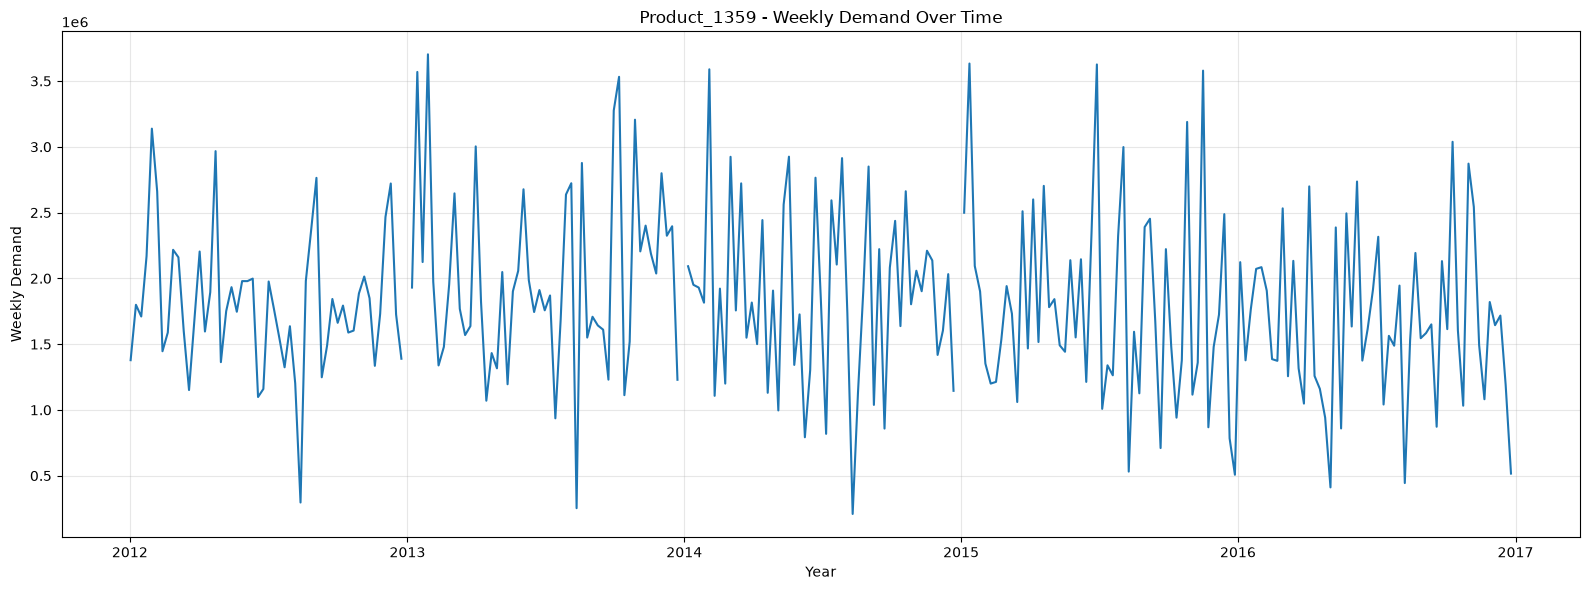

In [50]:

# Visualise weekly demand over time

plt.figure(figsize=(16, 6))

plt.plot(
    product_1359_complete.index.to_timestamp(),
    product_1359_complete['Weekly_Demand'],
    linewidth=1.5
)

plt.title('Product_1359 - Weekly Demand Over Time')
plt.xlabel('Year')
plt.ylabel('Weekly Demand')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [51]:

# Analyse weekly demand by calendar month

seasonal_data = product_1359_complete[
    ['Weekly_Demand']
].dropna().copy()

seasonal_data['Month'] = (
    seasonal_data.index.to_timestamp().month
)

monthly_seasonality = (
    seasonal_data.groupby('Month')['Weekly_Demand']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

month_names = {
    1: 'January', 2: 'February', 3: 'March',
    4: 'April', 5: 'May', 6: 'June',
    7: 'July', 8: 'August', 9: 'September',
    10: 'October', 11: 'November', 12: 'December'
}

monthly_seasonality.index = (
    monthly_seasonality.index.map(month_names)
)

display(monthly_seasonality)


,count,mean,median,std
Month,,,,
January,21,2227333.33,2072000.0,692061.94
February,21,1764476.19,1533000.0,609998.00
March,22,1792818.18,1706500.0,533306.37
April,22,1832045.45,1688500.0,648956.05
May,21,1768190.48,1842000.0,601943.49
June,22,1886954.55,1879000.0,658289.74
July,22,1722954.55,1660500.0,577667.35
August,22,1569090.91,1572000.0,853721.93
September,22,1779636.36,1661000.0,675189.75


In [52]:

# Compare monthly average weekly demand across individual years

year_month_data = product_1359_complete[
    ['Weekly_Demand']
].dropna().copy()

year_month_data['Year'] = (
    year_month_data.index.to_timestamp().year
)

year_month_data['Month'] = (
    year_month_data.index.to_timestamp().month
)

year_month_table = year_month_data.pivot_table(
    index='Year',
    columns='Month',
    values='Weekly_Demand',
    aggfunc='mean'
)

year_month_table.columns = [
    pd.Timestamp(2000, month, 1).strftime('%b')
    for month in year_month_table.columns
]

display(year_month_table.round(0))


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Year,,,,,,,,,,,,
2012,2038800.0,1977750.0,1648250.0,2005000.0,1852250.0,1558500.0,1650200.0,1461000.0,1835750.0,1706200.0,1732000.0,2075500.0
2013,2831500.0,1686250.0,1905000.0,1728400.0,1800250.0,2079500.0,1777000.0,1850750.0,1893200.0,2342250.0,2207750.0,2187000.0
2014,1947000.0,1954500.0,2153400.0,1745000.0,1956000.0,1686600.0,2107500.0,1244250.0,1809800.0,2134750.0,2076500.0,1549500.0
2015,2531750.0,1324500.0,1741800.0,2150000.0,1728250.0,2177800.0,1482750.0,1727800.0,1764250.0,1748000.0,1680400.0,1375750.0
2016,1834750.0,1856400.0,1438250.0,1514500.0,1557000.0,1909750.0,1602000.0,1531400.0,1559250.0,2032200.0,1734250.0,1266500.0


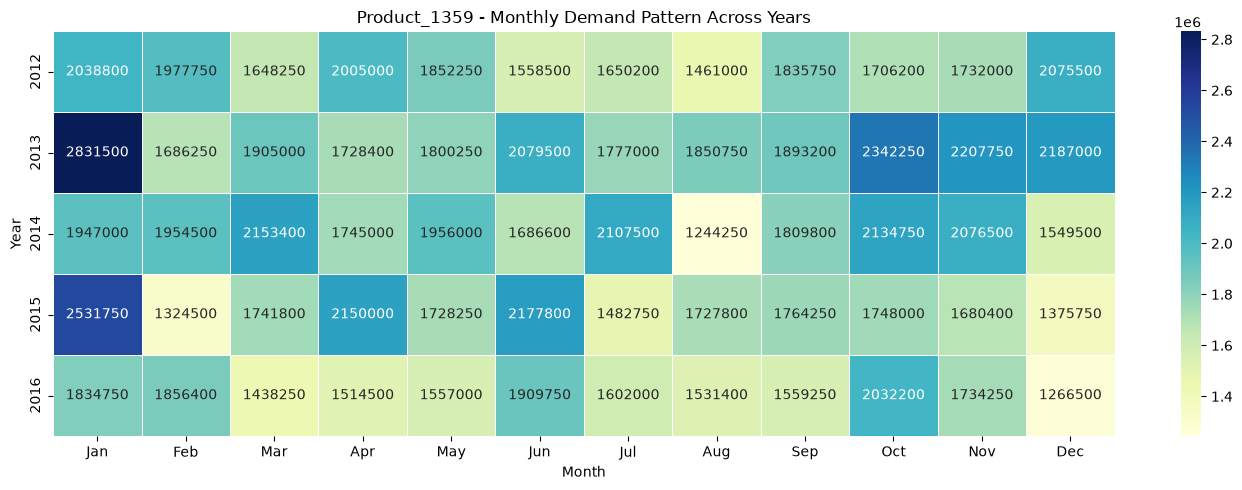

In [53]:

# Visualise monthly demand across years

plt.figure(figsize=(14, 5))

sns.heatmap(
    year_month_table,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Product_1359 - Monthly Demand Pattern Across Years')
plt.xlabel('Month')
plt.ylabel('Year')

plt.tight_layout()
plt.show()


In [54]:

# Analyse weekly demand autocorrelation

demand_series = product_1359_complete['Weekly_Demand']

lags = [1, 2, 4, 8, 13, 26, 52]

autocorrelation_results = pd.DataFrame({
    'Lag_Weeks': lags,
    'Autocorrelation': [
        demand_series.autocorr(lag=lag)
        for lag in lags
    ]
})

display(autocorrelation_results.round(4))


,Lag_Weeks,Autocorrelation
0,1,-0.0427
1,2,-0.0946
2,4,0.1062
3,8,-0.0285
4,13,0.0139
5,26,0.0054
6,52,0.1743


In [55]:

%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


<Figure size 1400x500 with 0 Axes>

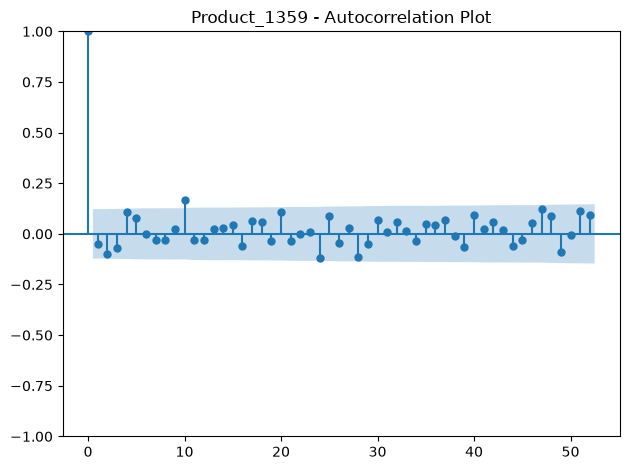

In [56]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(14, 5))

plot_acf(
    product_1359_complete['Weekly_Demand'],
    lags=52,
    missing='drop'
)

plt.title('Product_1359 - Autocorrelation Plot')
plt.tight_layout()
plt.show()


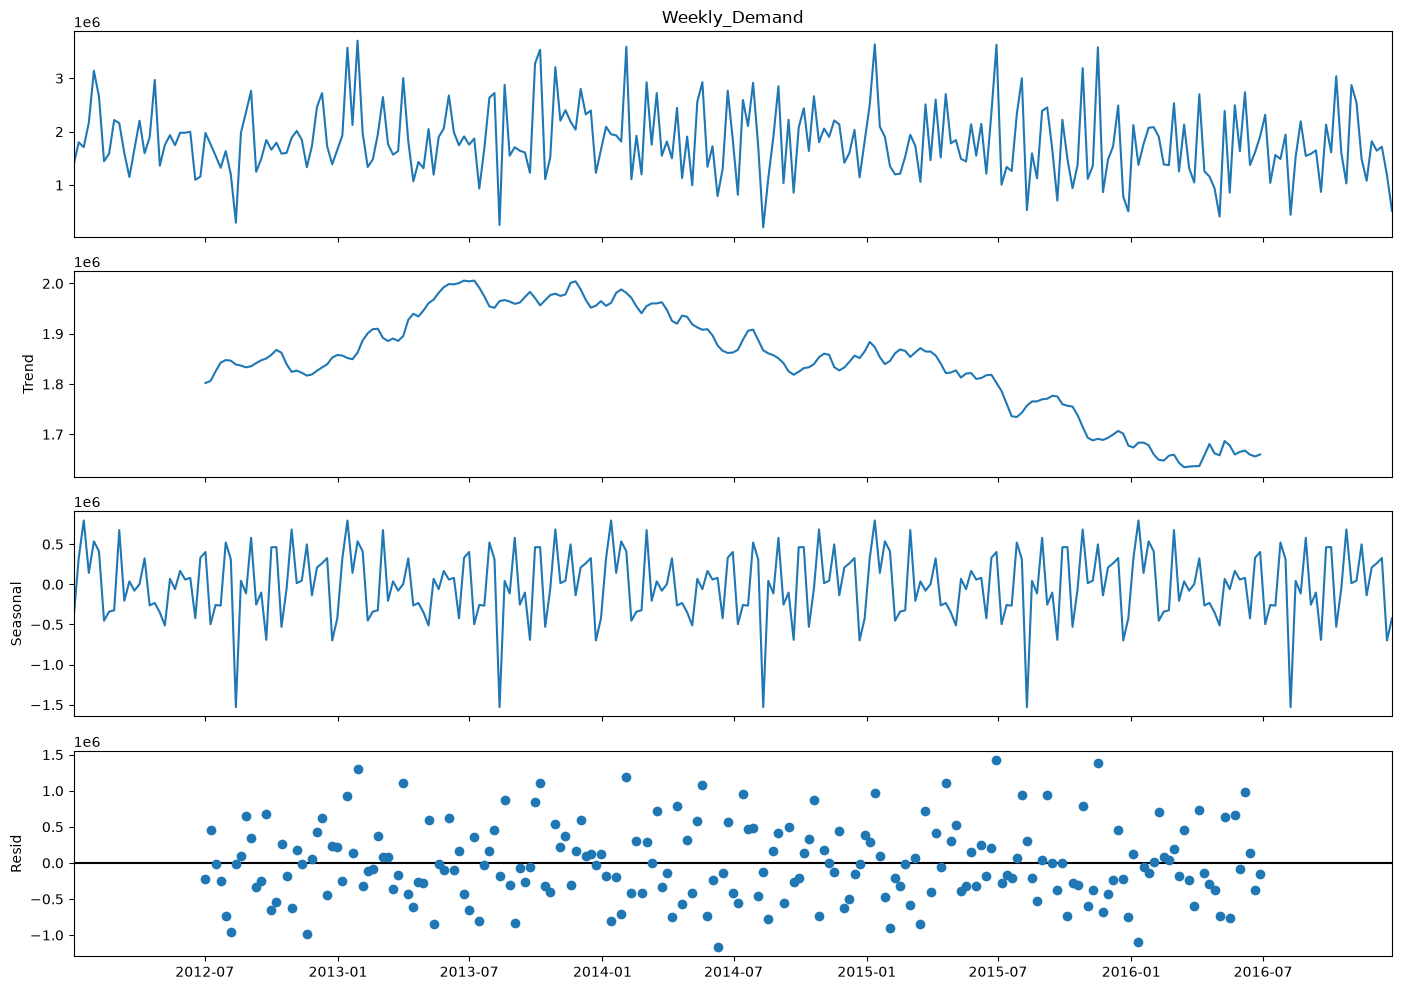

In [57]:


from statsmodels.tsa.seasonal import seasonal_decompose

# Create a temporary copy with a proper datetime index
weekly_for_decomposition = product_1359_complete[
    'Weekly_Demand'
].copy()

weekly_for_decomposition.index = (
    weekly_for_decomposition.index.to_timestamp()
)

# Interpolate missing weeks for this diagnostic only
weekly_for_decomposition = (
    weekly_for_decomposition.interpolate(method='linear')
)

# Perform seasonal decomposition
decomposition = seasonal_decompose(
    weekly_for_decomposition,
    model='additive',
    period=52
)

# Plot the components
fig = decomposition.plot()
fig.set_size_inches(14, 10)

plt.tight_layout()
plt.show()



In [58]:

%pip install pymannkendall


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [59]:

import pymannkendall as mk

# Remove missing weeks for the trend test
weekly_demand_test = (
    product_1359_complete['Weekly_Demand']
    .dropna()
)

# Perform Mann-Kendall trend test
trend_result = mk.original_test(weekly_demand_test)

print("Trend Test Result")
print("-------------------------")
print("Trend:", trend_result.trend)
print("Significance (p-value):", trend_result.p)
print("Test Statistic:", trend_result.Tau)
print("Z Statistic:", trend_result.z)
print("Sen's Slope:", trend_result.slope)


Trend Test Result
-------------------------
Trend: decreasing
Significance (p-value): 0.041070669410603555
Test Statistic: -0.08539197056073357
Z Statistic: -2.0428158653672717
Sen's Slope: -1074.0740740740741


In [60]:

# Calculate average demand per recorded transaction day

weekly_analysis = product_1359_complete.copy()

weekly_analysis['Demand_Per_Transaction_Day'] = (
    weekly_analysis['Weekly_Demand'] /
    weekly_analysis['Transaction_Days']
)

print("Demand per transaction day statistics:")

display(
    weekly_analysis['Demand_Per_Transaction_Day'].describe()
)

print("\nCorrelation between transaction days and weekly demand:")

print(
    weekly_analysis[
        ['Transaction_Days', 'Weekly_Demand']
    ].corr().round(4)
)


Demand per transaction day statistics:


count       258.000000
mean     384132.816537
std      139792.610434
min       52250.000000
25%      296050.000000
50%      363100.000000
75%      463150.000000
max      921000.000000
Name: Demand_Per_Transaction_Day, dtype: float64


Correlation between transaction days and weekly demand:
                  Transaction_Days  Weekly_Demand
Transaction_Days            1.0000         0.3549
Weekly_Demand               0.3549         1.0000


In [61]:

# Mann-Kendall trend test on demand per transaction day

daily_rate_series = (
    weekly_analysis['Demand_Per_Transaction_Day']
    .dropna()
)

rate_trend_result = mk.original_test(daily_rate_series)

print("Demand Per Transaction Day - Trend Test")
print("----------------------------------------")
print("Trend:", rate_trend_result.trend)
print("p-value:", rate_trend_result.p)
print("Kendall's Tau:", rate_trend_result.Tau)
print("Z Statistic:", rate_trend_result.z)
print("Sen's Slope:", rate_trend_result.slope)


Demand Per Transaction Day - Trend Test
----------------------------------------
Trend: no trend
p-value: 0.06802859540130712
Kendall's Tau: -0.07628268934938015
Z Statistic: -1.8248173589849586
Sen's Slope: -182.5581395348837


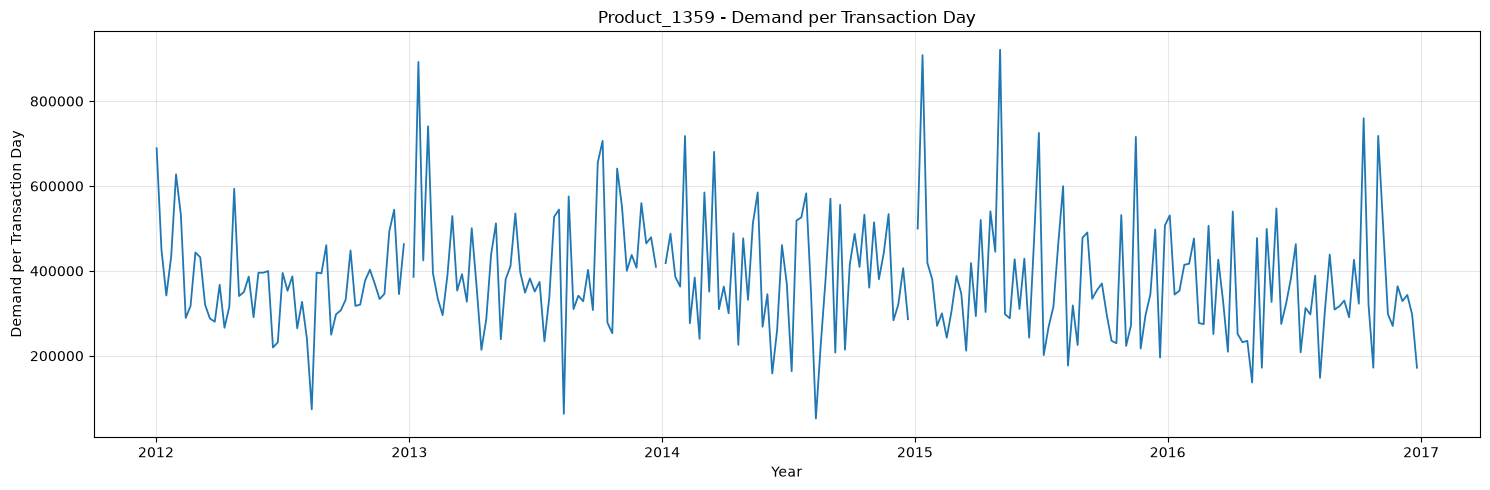

In [62]:

plt.figure(figsize=(15, 5))

plt.plot(
    weekly_analysis.index.to_timestamp(),
    weekly_analysis['Demand_Per_Transaction_Day'],
    linewidth=1.3
)

plt.title('Product_1359 - Demand per Transaction Day')
plt.xlabel('Year')
plt.ylabel('Demand per Transaction Day')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


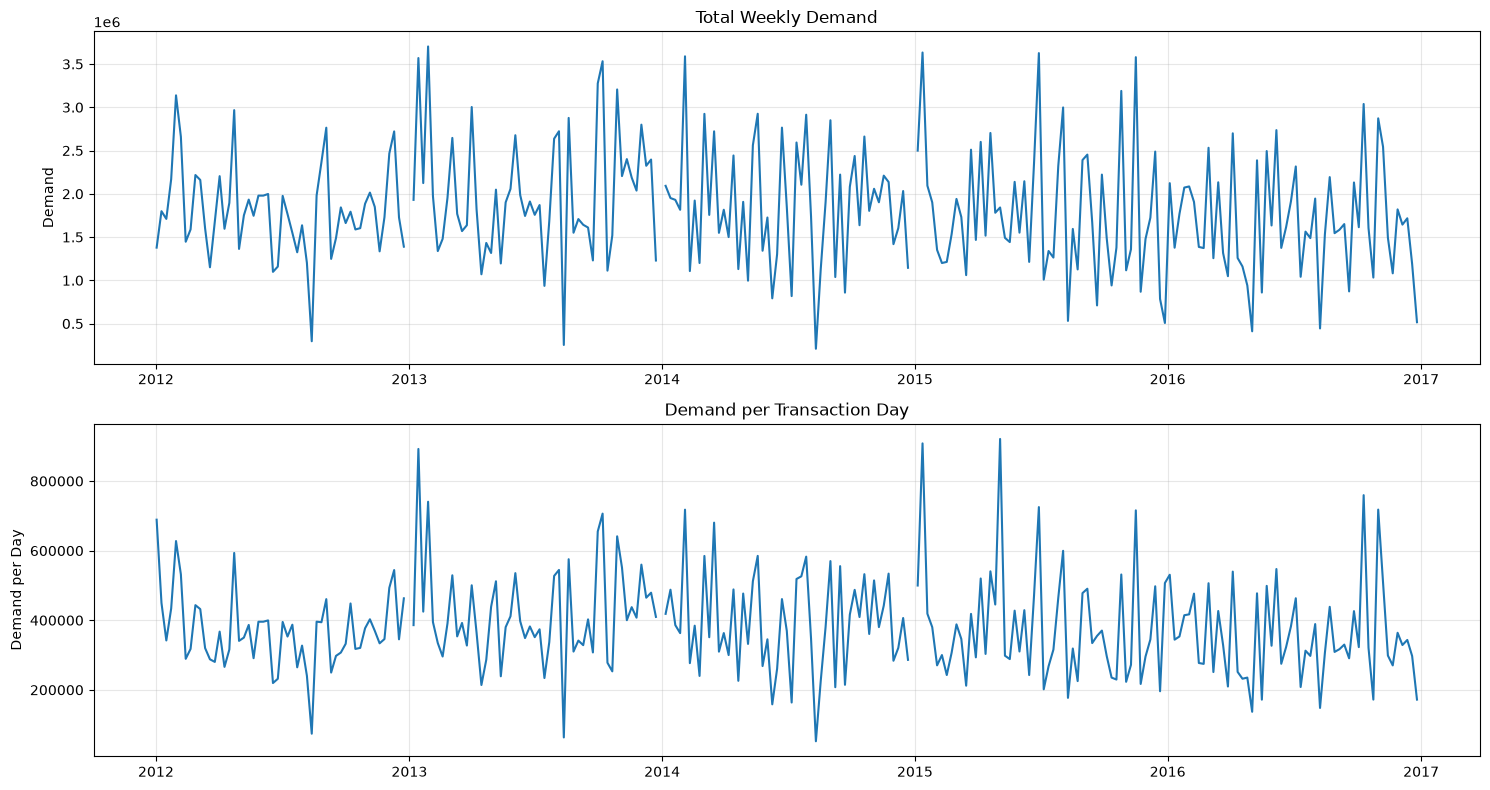

In [63]:

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

axes[0].plot(
    weekly_analysis.index.to_timestamp(),
    weekly_analysis['Weekly_Demand']
)
axes[0].set_title('Total Weekly Demand')
axes[0].set_ylabel('Demand')
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    weekly_analysis.index.to_timestamp(),
    weekly_analysis['Demand_Per_Transaction_Day']
)
axes[1].set_title('Demand per Transaction Day')
axes[1].set_ylabel('Demand per Day')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [64]:

# Create the final weekly forecasting dataset

forecast_data = product_1359_complete[
    ['Weekly_Demand']
].copy()

forecast_data.index = (
    forecast_data.index.to_timestamp()
)

forecast_data.index.name = 'Date'

print("Forecasting dataset shape:", forecast_data.shape)

print("\nDataset information:")
forecast_data.info()

print("\nFirst 5 observations:")
display(forecast_data.head())

print("\nLast 5 observations:")
display(forecast_data.tail())

print("\nMissing values:")
print(forecast_data.isnull().sum())


Forecasting dataset shape: (261, 1)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 261 entries, 2012-01-02 to 2016-12-26
Freq: W-MON
Data columns (total 1 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Weekly_Demand  258 non-null    float64
dtypes: float64(1)
memory usage: 4.1 KB

First 5 observations:


,Weekly_Demand
Date,
2012-01-02,1378000.0
2012-01-09,1799000.0
2012-01-16,1710000.0
2012-01-23,2169000.0
2012-01-30,3138000.0



Last 5 observations:


,Weekly_Demand
Date,
2016-11-28,1820000.0
2016-12-05,1644000.0
2016-12-12,1717000.0
2016-12-19,1189000.0
2016-12-26,516000.0



Missing values:
Weekly_Demand    3
dtype: int64


In [65]:

# Create a separate modelling series

model_series = forecast_data['Weekly_Demand'].interpolate(
    method='time'
)

print("Original missing values:",
      forecast_data['Weekly_Demand'].isnull().sum())

print("Missing values after interpolation:",
      model_series.isnull().sum())

print("\nEstimated values for missing weeks:")

imputed_weeks = forecast_data[
    forecast_data['Weekly_Demand'].isnull()
].index

display(
    pd.DataFrame({
        'Original_Demand': forecast_data.loc[
            imputed_weeks, 'Weekly_Demand'
        ],
        'Estimated_Demand': model_series.loc[imputed_weeks]
    })
)


Original missing values: 3
Missing values after interpolation: 0

Estimated values for missing weeks:


,Original_Demand,Estimated_Demand
Date,,
2012-12-31,NaN,1659500.0
2013-12-30,NaN,1660500.0
2014-12-29,NaN,1822000.0


In [66]:

# Chronological train-test split

split_index = int(len(model_series) * 0.80)

train = model_series.iloc[:split_index]
test = model_series.iloc[split_index:]

print("Total observations:", len(model_series))

print("\nTraining observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())


Total observations: 261

Training observations: 208
Testing observations: 53

Training period:
2012-01-02 00:00:00 to 2015-12-21 00:00:00

Testing period:
2015-12-28 00:00:00 to 2016-12-26 00:00:00


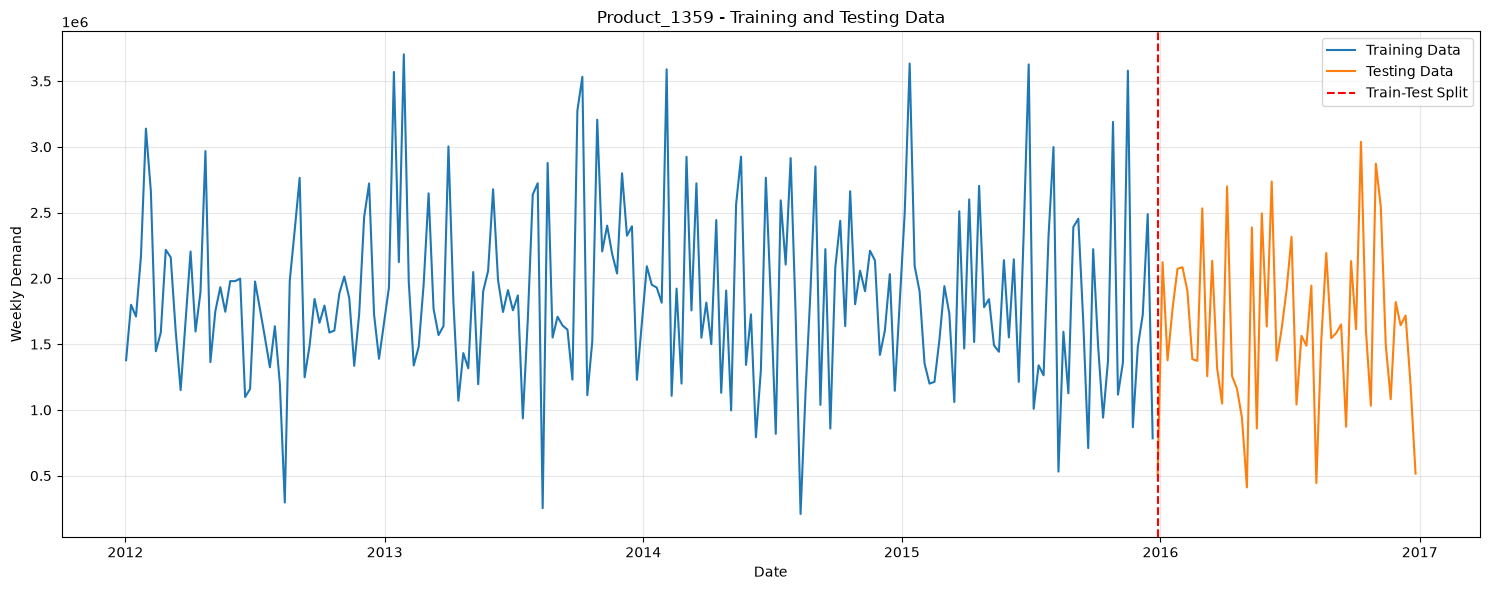

In [67]:

plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train,
    label='Training Data'
)

plt.plot(
    test.index,
    test,
    label='Testing Data'
)

plt.axvline(
    test.index[0],
    color='red',
    linestyle='--',
    label='Train-Test Split'
)

plt.title('Product_1359 - Training and Testing Data')
plt.xlabel('Date')
plt.ylabel('Weekly Demand')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [68]:

# Naive forecasting baseline

naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index
)

print("Last observed training demand:", train.iloc[-1])

print("\nFirst 10 actual vs predicted values:")

baseline_comparison = pd.DataFrame({
    'Actual_Demand': test,
    'Predicted_Demand': naive_forecast
})

display(baseline_comparison.head(10))


Last observed training demand: 784000.0

First 10 actual vs predicted values:


,Actual_Demand,Predicted_Demand
Date,,
2015-12-28,507000.0,784000.0
2016-01-04,2123000.0,784000.0
2016-01-11,1377000.0,784000.0
2016-01-18,1767000.0,784000.0
2016-01-25,2072000.0,784000.0
2016-02-01,2085000.0,784000.0
2016-02-08,1906000.0,784000.0
2016-02-15,1386000.0,784000.0
2016-02-22,1373000.0,784000.0


In [69]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Calculate evaluation metrics

mae = mean_absolute_error(test, naive_forecast)

rmse = np.sqrt(mean_squared_error(test, naive_forecast))

mape = mean_absolute_percentage_error(
    test,
    naive_forecast
) * 100

print("NAIVE BASELINE MODEL PERFORMANCE")
print("--------------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("MAPE:", round(mape, 2), "%")


NAIVE BASELINE MODEL PERFORMANCE
--------------------------------
MAE: 901754.72
RMSE: 1057612.25
MAPE: 51.35 %


In [70]:

# Seasonal Naive Forecast (52-week seasonality)

seasonal_period = 52

seasonal_values = train.iloc[-seasonal_period:].values

seasonal_forecast_values = np.resize(
    seasonal_values,
    len(test)
)

seasonal_forecast = pd.Series(
    seasonal_forecast_values,
    index=test.index
)

print("Seasonal Naive Forecast")

comparison = pd.DataFrame({
    'Actual_Demand': test,
    'Predicted_Demand': seasonal_forecast
})

display(comparison.head(10))


Seasonal Naive Forecast


,Actual_Demand,Predicted_Demand
Date,,
2015-12-28,507000.0,1822000.0
2016-01-04,2123000.0,2499000.0
2016-01-11,1377000.0,3633000.0
2016-01-18,1767000.0,2094000.0
2016-01-25,2072000.0,1901000.0
2016-02-01,2085000.0,1352000.0
2016-02-08,1906000.0,1200000.0
2016-02-15,1386000.0,1213000.0
2016-02-22,1373000.0,1533000.0


In [71]:

# Evaluate Seasonal Naive model

seasonal_mae = mean_absolute_error(
    test, seasonal_forecast
)

seasonal_rmse = np.sqrt(
    mean_squared_error(test, seasonal_forecast)
)

seasonal_mape = mean_absolute_percentage_error(
    test, seasonal_forecast
) * 100

print("SEASONAL NAIVE MODEL PERFORMANCE")
print("--------------------------------")
print("MAE:", round(seasonal_mae, 2))
print("RMSE:", round(seasonal_rmse, 2))
print("MAPE:", round(seasonal_mape, 2), "%")


SEASONAL NAIVE MODEL PERFORMANCE
--------------------------------
MAE: 736113.21
RMSE: 959458.26
MAPE: 57.32 %


In [72]:

# Compare baseline forecasting models

baseline_results = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        'Seasonal Naive Forecast'
    ],
    'MAE': [
        mae,
        seasonal_mae
    ],
    'RMSE': [
        rmse,
        seasonal_rmse
    ],
    'MAPE': [
        mape,
        seasonal_mape
    ]
})

display(
    baseline_results.round(2)
)


,Model,MAE,RMSE,MAPE
0,Naive Forecast,901754.72,1057612.25,51.35
1,Seasonal Naive Forecast,736113.21,959458.26,57.32


In [73]:

# 4-week Moving Average Forecast

window = 4

history = list(train.values)
moving_average_predictions = []

for i in range(len(test)):
    prediction = np.mean(history[-window:])
    moving_average_predictions.append(prediction)
    history.append(prediction)

moving_average_forecast = pd.Series(
    moving_average_predictions,
    index=test.index
)

print("Moving Average Forecast")

display(pd.DataFrame({
    'Actual_Demand': test,
    'Predicted_Demand': moving_average_forecast
}).head(10))


Moving Average Forecast


,Actual_Demand,Predicted_Demand
Date,,
2015-12-28,507000.0,1.618750e+06
2016-01-04,2123000.0,1.653688e+06
2016-01-11,1377000.0,1.636109e+06
2016-01-18,1767000.0,1.423137e+06
2016-01-25,2072000.0,1.582921e+06
2016-02-01,2085000.0,1.573964e+06
2016-02-08,1906000.0,1.554033e+06
2016-02-15,1386000.0,1.533513e+06
2016-02-22,1373000.0,1.561108e+06


In [74]:

# Evaluate Moving Average model

ma_mae = mean_absolute_error(
    test, moving_average_forecast
)

ma_rmse = np.sqrt(
    mean_squared_error(test, moving_average_forecast)
)

ma_mape = mean_absolute_percentage_error(
    test, moving_average_forecast
) * 100

print("MOVING AVERAGE MODEL PERFORMANCE")
print("---------------------------------")
print("MAE:", round(ma_mae, 2))
print("RMSE:", round(ma_rmse, 2))
print("MAPE:", round(ma_mape, 2), "%")


MOVING AVERAGE MODEL PERFORMANCE
---------------------------------
MAE: 494044.47
RMSE: 630653.84
MAPE: 41.65 %


In [75]:

# Add Moving Average results

new_result = pd.DataFrame({
    'Model': ['4-Week Moving Average'],
    'MAE': [ma_mae],
    'RMSE': [ma_rmse],
    'MAPE': [ma_mape]
})

baseline_results = pd.concat(
    [baseline_results, new_result],
    ignore_index=True
)

display(baseline_results.round(2))


,Model,MAE,RMSE,MAPE
0,Naive Forecast,901754.72,1057612.25,51.35
1,Seasonal Naive Forecast,736113.21,959458.26,57.32
2,4-Week Moving Average,494044.47,630653.84,41.65


In [77]:

import statsmodels
print("Statsmodels version:", statsmodels.__version__)
print("Python version:", __import__('sys').version)

Statsmodels version: 0.15.0
Python version: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


In [78]:

# Simple Exponential Smoothing (manual implementation)

alpha = 0.3

# Start with the first training observation
smoothed_level = train.iloc[0]

# Update the smoothed level using training data only
for actual_value in train.iloc[1:]:
    smoothed_level = (
        alpha * actual_value
        + (1 - alpha) * smoothed_level
    )

# Forecast all test weeks using the final smoothed level
ses_forecast = pd.Series(
    smoothed_level,
    index=test.index
)

print("Smoothing Level:", round(smoothed_level, 2))
print("\nFirst 10 forecasts:")

display(pd.DataFrame({
    'Actual_Demand': test,
    'Predicted_Demand': ses_forecast
}).head(10))


Smoothing Level: 1594519.81

First 10 forecasts:


,Actual_Demand,Predicted_Demand
Date,,
2015-12-28,507000.0,1.594520e+06
2016-01-04,2123000.0,1.594520e+06
2016-01-11,1377000.0,1.594520e+06
2016-01-18,1767000.0,1.594520e+06
2016-01-25,2072000.0,1.594520e+06
2016-02-01,2085000.0,1.594520e+06
2016-02-08,1906000.0,1.594520e+06
2016-02-15,1386000.0,1.594520e+06
2016-02-22,1373000.0,1.594520e+06


In [79]:
# Evaluate Simple Exponential Smoothing

ses_mae = np.mean(np.abs(test.values - ses_forecast.values))

ses_rmse = np.sqrt(
    np.mean((test.values - ses_forecast.values) ** 2)
)

ses_mape = np.mean(
    np.abs((test.values - ses_forecast.values) / test.values)
) * 100

print("Simple Exponential Smoothing Results")
print("------------------------------------")
print("MAE:", round(ses_mae, 2))
print("RMSE:", round(ses_rmse, 2))
print("MAPE:", round(ses_mape, 2), "%")

Simple Exponential Smoothing Results
------------------------------------
MAE: 489518.49
RMSE: 625027.54
MAPE: 42.27 %


In [80]:
new_result = pd.DataFrame({
    'Model': ['Simple Exponential Smoothing'],
    'MAE': [ses_mae],
    'RMSE': [ses_rmse],
    'MAPE': [ses_mape]
})

baseline_results = pd.concat(
    [baseline_results, new_result],
    ignore_index=True
)

display(baseline_results.round(2))

,Model,MAE,RMSE,MAPE
0,Naive Forecast,901754.72,1057612.25,51.35
1,Seasonal Naive Forecast,736113.21,959458.26,57.32
2,4-Week Moving Average,494044.47,630653.84,41.65
3,Simple Exponential Smoothing,489518.49,625027.54,42.27


In [81]:

# Holt's Linear Trend Method

alpha = 0.3
beta = 0.1

# Initialise level and trend using training data
level = train.iloc[0]
trend = train.iloc[1] - train.iloc[0]

holt_predictions = []

# Update level and trend using training data
for actual_value in train.iloc[1:]:
    previous_level = level

    level = (
        alpha * actual_value
        + (1 - alpha) * (level + trend)
    )

    trend = (
        beta * (level - previous_level)
        + (1 - beta) * trend
    )

# Forecast the complete testing period
holt_forecast_values = [
    level + (step * trend)
    for step in range(1, len(test) + 1)
]

holt_forecast = pd.Series(
    holt_forecast_values,
    index=test.index
)

print("Final Level:", round(level, 2))
print("Estimated Trend:", round(trend, 2))

display(pd.DataFrame({
    'Actual_Demand': test,
    'Holt_Predicted_Demand': holt_forecast
}).head(10))


Final Level: 1610342.61
Estimated Trend: -15804.41


,Actual_Demand,Holt_Predicted_Demand
Date,,
2015-12-28,507000.0,1.594538e+06
2016-01-04,2123000.0,1.578734e+06
2016-01-11,1377000.0,1.562929e+06
2016-01-18,1767000.0,1.547125e+06
2016-01-25,2072000.0,1.531321e+06
2016-02-01,2085000.0,1.515516e+06
2016-02-08,1906000.0,1.499712e+06
2016-02-15,1386000.0,1.483907e+06
2016-02-22,1373000.0,1.468103e+06


In [82]:
# Evaluate Holt's Linear Trend model

holt_mae = np.mean(
    np.abs(test.values - holt_forecast.values)
)

holt_rmse = np.sqrt(
    np.mean((test.values - holt_forecast.values) ** 2)
)

holt_mape = np.mean(
    np.abs((test.values - holt_forecast.values) / test.values)
) * 100

print("Holt's Linear Trend Results")
print("---------------------------")
print("MAE:", round(holt_mae, 2))
print("RMSE:", round(holt_rmse, 2))
print("MAPE:", round(holt_mape, 2), "%")

Holt's Linear Trend Results
---------------------------
MAE: 650732.7
RMSE: 808357.21
MAPE: 42.88 %


In [83]:
new_result = pd.DataFrame({
    'Model': ["Holt's Linear Trend"],
    'MAE': [holt_mae],
    'RMSE': [holt_rmse],
    'MAPE': [holt_mape]
})

baseline_results = pd.concat(
    [baseline_results, new_result],
    ignore_index=True
)

display(baseline_results.round(2))

,Model,MAE,RMSE,MAPE
0,Naive Forecast,901754.72,1057612.25,51.35
1,Seasonal Naive Forecast,736113.21,959458.26,57.32
2,4-Week Moving Average,494044.47,630653.84,41.65
3,Simple Exponential Smoothing,489518.49,625027.54,42.27
4,Holt's Linear Trend,650732.70,808357.21,42.88


In [84]:

# Find the best alpha using training data only

alpha_values = np.arange(0.05, 1.00, 0.05)

alpha_results = []

for alpha_value in alpha_values:

    history = list(train.values)
    predictions = []

    for i in range(1, len(history)):
        # Forecast using information available before this observation
        predictions.append(history[i - 1])

    # Calculate exponentially weighted forecasts
    level = train.iloc[0]
    errors = []

    for actual_value in train.iloc[1:]:
        prediction = level
        errors.append(abs(actual_value - prediction))

        level = (
            alpha_value * actual_value
            + (1 - alpha_value) * level
        )

    alpha_results.append({
        'Alpha': alpha_value,
        'Training_MAE': np.mean(errors)
    })

alpha_results_df = pd.DataFrame(alpha_results)

display(
    alpha_results_df.sort_values(
        'Training_MAE'
    ).head(10).round(2)
)



,Alpha,Training_MAE
0,0.05,528031.97
1,0.10,537880.13
2,0.15,547784.01
3,0.20,558263.71
4,0.25,569682.89
5,0.30,580672.00
6,0.35,591760.23
7,0.40,602462.21
8,0.45,612769.68
9,0.50,621970.41


In [85]:
# Optimised Simple Exponential Smoothing

best_alpha = 0.05

level = train.iloc[0]

for actual_value in train.iloc[1:]:
    level = (
        best_alpha * actual_value
        + (1 - best_alpha) * level
    )

# Forecast the testing period
optimized_ses_forecast = pd.Series(
    level,
    index=test.index
)

# Calculate evaluation metrics
optimized_ses_mae = np.mean(
    np.abs(test.values - optimized_ses_forecast.values)
)

optimized_ses_rmse = np.sqrt(
    np.mean((test.values - optimized_ses_forecast.values) ** 2)
)

optimized_ses_mape = np.mean(
    np.abs((test.values - optimized_ses_forecast.values) / test.values)
) * 100

print("Optimised Alpha:", best_alpha)
print("Forecast Level:", round(level, 2))
print("MAE:", round(optimized_ses_mae, 2))
print("RMSE:", round(optimized_ses_rmse, 2))
print("MAPE:", round(optimized_ses_mape, 2), "%")

Optimised Alpha: 0.05
Forecast Level: 1761323.66
MAE: 518456.75
RMSE: 635518.06
MAPE: 48.46 %


In [86]:
optimized_result = pd.DataFrame({
    'Model': ['Optimised SES (Alpha 0.05)'],
    'MAE': [optimized_ses_mae],
    'RMSE': [optimized_ses_rmse],
    'MAPE': [optimized_ses_mape]
})

baseline_results = pd.concat(
    [baseline_results, optimized_result],
    ignore_index=True
)

display(
    baseline_results.sort_values(
        by='MAE'
    ).round(2)
)

,Model,MAE,RMSE,MAPE
3,Simple Exponential Smoothing,489518.49,625027.54,42.27
2,4-Week Moving Average,494044.47,630653.84,41.65
5,Optimised SES (Alpha 0.05),518456.75,635518.06,48.46
4,Holt's Linear Trend,650732.70,808357.21,42.88
1,Seasonal Naive Forecast,736113.21,959458.26,57.32
0,Naive Forecast,901754.72,1057612.25,51.35


In [87]:

# 52-Week Seasonal Moving Average Forecast

seasonal_window = 52

history = list(train.values)
seasonal_ma_predictions = []

for i in range(len(test)):

    prediction = np.mean(history[-seasonal_window:])

    seasonal_ma_predictions.append(prediction)

    history.append(prediction)

seasonal_ma_forecast = pd.Series(
    seasonal_ma_predictions,
    index=test.index
)

print("First 10 Seasonal Moving Average Forecasts:")

display(pd.DataFrame({
    'Actual_Demand': test,
    'Predicted_Demand': seasonal_ma_forecast
}).head(10))


First 10 Seasonal Moving Average Forecasts:


,Actual_Demand,Predicted_Demand
Date,,
2015-12-28,507000.0,1.814904e+06
2016-01-04,2123000.0,1.814767e+06
2016-01-11,1377000.0,1.801609e+06
2016-01-18,1767000.0,1.766390e+06
2016-01-25,2072000.0,1.760090e+06
2016-02-01,2085000.0,1.757380e+06
2016-02-08,1906000.0,1.765176e+06
2016-02-15,1386000.0,1.776045e+06
2016-02-22,1373000.0,1.786872e+06


In [88]:
# Evaluate 52-Week Seasonal Moving Average

seasonal_ma_mae = np.mean(
    np.abs(test.values - seasonal_ma_forecast.values)
)

seasonal_ma_rmse = np.sqrt(
    np.mean((test.values - seasonal_ma_forecast.values) ** 2)
)

seasonal_ma_mape = np.mean(
    np.abs((test.values - seasonal_ma_forecast.values) / test.values)
) * 100

print("52-Week Moving Average Results")
print("--------------------------------")
print("MAE:", round(seasonal_ma_mae, 2))
print("RMSE:", round(seasonal_ma_rmse, 2))
print("MAPE:", round(seasonal_ma_mape, 2), "%")

52-Week Moving Average Results
--------------------------------
MAE: 520712.61
RMSE: 637416.75
MAPE: 48.8 %


In [89]:
new_result = pd.DataFrame({
    'Model': ['52-Week Moving Average'],
    'MAE': [seasonal_ma_mae],
    'RMSE': [seasonal_ma_rmse],
    'MAPE': [seasonal_ma_mape]
})

baseline_results = pd.concat(
    [baseline_results, new_result],
    ignore_index=True
)

display(
    baseline_results.sort_values(
        by='MAE'
    ).round(2)
)

,Model,MAE,RMSE,MAPE
3,Simple Exponential Smoothing,489518.49,625027.54,42.27
2,4-Week Moving Average,494044.47,630653.84,41.65
5,Optimised SES (Alpha 0.05),518456.75,635518.06,48.46
6,52-Week Moving Average,520712.61,637416.75,48.80
4,Holt's Linear Trend,650732.70,808357.21,42.88
1,Seasonal Naive Forecast,736113.21,959458.26,57.32
0,Naive Forecast,901754.72,1057612.25,51.35


In [90]:
# Check seasonal pattern in training data

seasonal_period = 52

print("Training observations:", len(train))
print("Seasonal period:", seasonal_period)
print("Complete seasonal cycles:", len(train) // seasonal_period)

# Average demand for each seasonal week
seasonal_pattern = train.groupby(
    np.arange(len(train)) % seasonal_period
).mean()

print("\nFirst 10 seasonal averages:")

display(seasonal_pattern.head(10).round(2))

Training observations: 208
Seasonal period: 52
Complete seasonal cycles: 4

First 10 seasonal averages:


0    1630000.0
1    2080000.0
2    2715750.0
3    2079250.0
4    2639250.0
5    2393750.0
6    1272750.0
7    1550500.0
8    1726000.0
9    2417750.0
Name: Weekly_Demand, dtype: float64

In [91]:

# Initialise Holt-Winters components

seasonal_period = 52

# Initial level: average of first 52 weeks
initial_level = train.iloc[:52].mean()

# Initial trend: average weekly change across first 52 weeks
initial_trend = (
    train.iloc[52:104].mean() - train.iloc[:52].mean()
) / 52

# Initial seasonal components
first_season = train.iloc[:52].values
initial_seasonal = first_season - initial_level

print("Initial Level:", round(initial_level, 2))
print("Initial Trend:", round(initial_trend, 2))
print("First 10 Seasonal Components:")

display(pd.Series(initial_seasonal[:10]).round(2))


Initial Level: 1799326.92
Initial Trend: 3938.05
First 10 Seasonal Components:


0    -421326.92
1       -326.92
2     -89326.92
3     369673.08
4    1338673.08
5     860673.08
6    -353326.92
7    -211326.92
8     417673.08
9     360673.08
dtype: float64

In [92]:

# Holt-Winters Additive Model

alpha = 0.3
beta = 0.1
gamma = 0.1
seasonal_period = 52

# Initialise components
level = initial_level
trend = initial_trend
seasonals = list(initial_seasonal)

# Update components using training data after first season
for t in range(seasonal_period, len(train)):

    actual = train.iloc[t]
    seasonal = seasonals[t % seasonal_period]

    previous_level = level

    # Update level
    level = (
        alpha * (actual - seasonal)
        + (1 - alpha) * (level + trend)
    )

    # Update trend
    trend = (
        beta * (level - previous_level)
        + (1 - beta) * trend
    )

    # Update seasonal component
    seasonals[t % seasonal_period] = (
        gamma * (actual - level)
        + (1 - gamma) * seasonal
    )

print("Final Level:", round(level, 2))
print("Final Trend:", round(trend, 2))
print("Seasonal Components:", len(seasonals))


Final Level: 1546805.17
Final Trend: -21948.05
Seasonal Components: 52


In [93]:

# Generate Holt-Winters forecasts for the test period

holt_winters_predictions = []

for step in range(1, len(test) + 1):

    seasonal_index = (len(train) + step - 1) % seasonal_period

    prediction = (
        level
        + step * trend
        + seasonals[seasonal_index]
    )

    holt_winters_predictions.append(prediction)

holt_winters_forecast = pd.Series(
    holt_winters_predictions,
    index=test.index
)

print("Holt-Winters Forecasts")
print("----------------------")

display(pd.DataFrame({
    'Actual_Demand': test,
    'Predicted_Demand': holt_winters_forecast
}).head(10))


Holt-Winters Forecasts
----------------------


,Actual_Demand,Predicted_Demand
Date,,
2015-12-28,507000.0,1.174565e+06
2016-01-04,2123000.0,1.563679e+06
2016-01-11,1377000.0,1.620649e+06
2016-01-18,1767000.0,1.700189e+06
2016-01-25,2072000.0,2.564524e+06
2016-02-01,2085000.0,2.194465e+06
2016-02-08,1906000.0,1.013061e+06
2016-02-15,1386000.0,1.180031e+06
2016-02-22,1373000.0,1.667136e+06


In [94]:

# Evaluate Holt-Winters model

hw_mae = np.mean(
    np.abs(test.values - holt_winters_forecast.values)
)

hw_rmse = np.sqrt(
    np.mean((test.values - holt_winters_forecast.values) ** 2)
)

hw_mape = np.mean(
    np.abs(
        (test.values - holt_winters_forecast.values)
        / test.values
    )
) * 100

print("Holt-Winters Model Results")
print("--------------------------")
print("MAE:", round(hw_mae, 2))
print("RMSE:", round(hw_rmse, 2))
print("MAPE:", round(hw_mape, 2), "%")


Holt-Winters Model Results
--------------------------
MAE: 854347.91
RMSE: 1035776.02
MAPE: 56.5 %


In [95]:
new_result = pd.DataFrame({
    'Model': ['Holt-Winters Additive'],
    'MAE': [hw_mae],
    'RMSE': [hw_rmse],
    'MAPE': [hw_mape]
})

baseline_results = pd.concat(
    [baseline_results, new_result],
    ignore_index=True
)

display(
    baseline_results.sort_values(
        by='MAE'
    ).round(2)
)


,Model,MAE,RMSE,MAPE
3,Simple Exponential Smoothing,489518.49,625027.54,42.27
2,4-Week Moving Average,494044.47,630653.84,41.65
5,Optimised SES (Alpha 0.05),518456.75,635518.06,48.46
6,52-Week Moving Average,520712.61,637416.75,48.80
4,Holt's Linear Trend,650732.70,808357.21,42.88
1,Seasonal Naive Forecast,736113.21,959458.26,57.32
7,Holt-Winters Additive,854347.91,1035776.02,56.50
0,Naive Forecast,901754.72,1057612.25,51.35


In [96]:
# Check actual test values before final evaluation

print("Test observations:", len(test))
print("Zero-demand weeks:", (test == 0).sum())
print("Negative-demand weeks:", (test < 0).sum())
print("Missing test values:", test.isna().sum())

print("\nTest demand summary:")
display(test.describe().round(2))

Test observations: 53
Zero-demand weeks: 0
Negative-demand weeks: 0
Missing test values: 0

Test demand summary:


count         53.00
mean     1638283.02
std       629460.13
min       411000.00
25%      1256000.00
50%      1605000.00
75%      2085000.00
max      3038000.00
Name: Weekly_Demand, dtype: float64

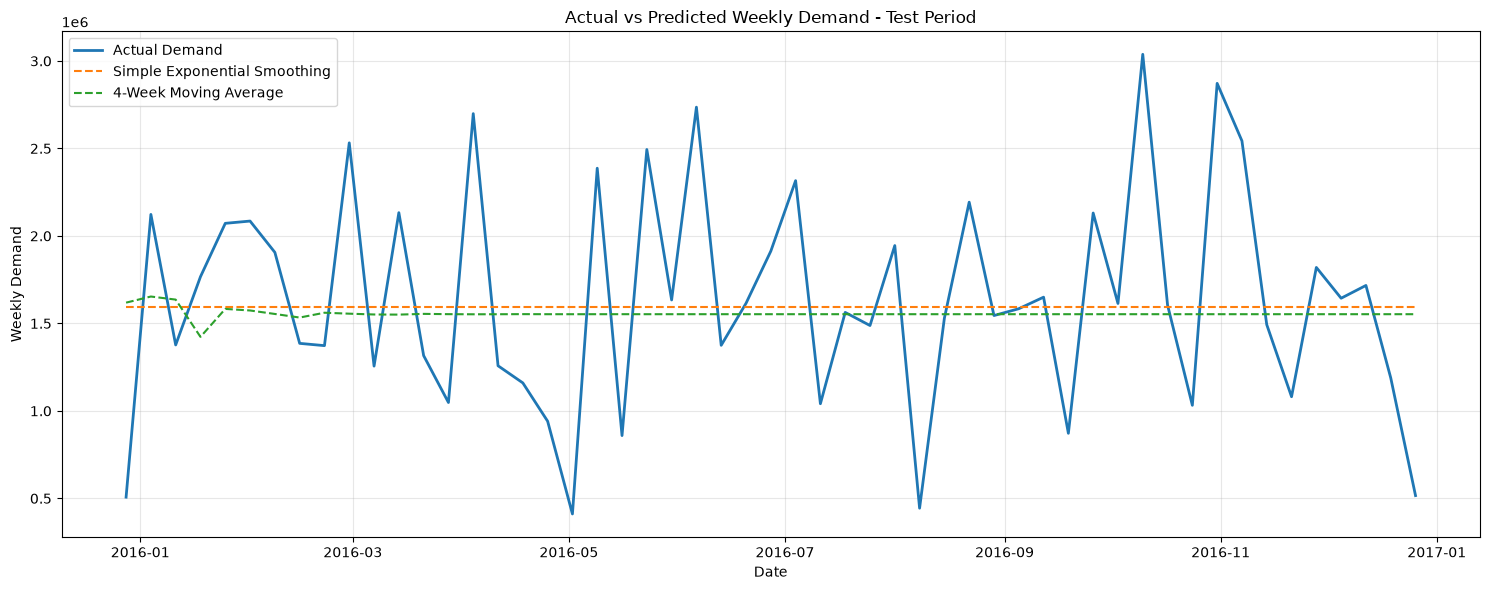

In [97]:

plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test.values,
    label='Actual Demand',
    linewidth=2
)

plt.plot(
    test.index,
    ses_forecast.values,
    label='Simple Exponential Smoothing',
    linestyle='--'
)

plt.plot(
    test.index,
    moving_average_forecast.values,
    label='4-Week Moving Average',
    linestyle='--'
)

plt.title('Actual vs Predicted Weekly Demand - Test Period')
plt.xlabel('Date')
plt.ylabel('Weekly Demand')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [98]:

# Create an internal validation split

validation_split = int(len(train) * 0.80)

train_inner = train.iloc[:validation_split]
validation = train.iloc[validation_split:]

print("Internal Training Observations:", len(train_inner))
print("Validation Observations:", len(validation))

print("\nInternal Training Period:")
print(train_inner.index.min(), "to", train_inner.index.max())

print("\nValidation Period:")
print(validation.index.min(), "to", validation.index.max())

print("\nFinal Test Observations:", len(test))


Internal Training Observations: 166
Validation Observations: 42

Internal Training Period:
2012-01-02 00:00:00 to 2015-03-02 00:00:00

Validation Period:
2015-03-09 00:00:00 to 2015-12-21 00:00:00

Final Test Observations: 53


In [99]:

# SES validation forecast

alpha = 0.3

level = train_inner.iloc[0]

for actual_value in train_inner.iloc[1:]:
    level = (
        alpha * actual_value
        + (1 - alpha) * level
    )

ses_validation_forecast = pd.Series(
    level,
    index=validation.index
)

# Validation metrics
ses_val_mae = np.mean(
    np.abs(validation.values - ses_validation_forecast.values)
)

ses_val_rmse = np.sqrt(
    np.mean((validation.values - ses_validation_forecast.values) ** 2)
)

ses_val_mape = np.mean(
    np.abs(
        (validation.values - ses_validation_forecast.values)
        / validation.values
    )
) * 100

print("SES Validation Results")
print("----------------------")
print("MAE:", round(ses_val_mae, 2))
print("RMSE:", round(ses_val_rmse, 2))
print("MAPE:", round(ses_val_mape, 2), "%")


SES Validation Results
----------------------
MAE: 597625.28
RMSE: 757791.77
MAPE: 38.99 %


In [100]:

# 4-Week Moving Average validation forecast

window = 4

history = list(train_inner.values)
ma_validation_predictions = []

for i in range(len(validation)):

    prediction = np.mean(history[-window:])

    ma_validation_predictions.append(prediction)

    history.append(prediction)

ma_validation_forecast = pd.Series(
    ma_validation_predictions,
    index=validation.index
)

# Calculate validation metrics
ma_val_mae = np.mean(
    np.abs(validation.values - ma_validation_forecast.values)
)

ma_val_rmse = np.sqrt(
    np.mean((validation.values - ma_validation_forecast.values) ** 2)
)

ma_val_mape = np.mean(
    np.abs(
        (validation.values - ma_validation_forecast.values)
        / validation.values
    )
) * 100

print("4-Week Moving Average Validation Results")
print("-----------------------------------------")
print("MAE:", round(ma_val_mae, 2))
print("RMSE:", round(ma_val_rmse, 2))
print("MAPE:", round(ma_val_mape, 2), "%")


4-Week Moving Average Validation Results
-----------------------------------------
MAE: 596473.26
RMSE: 773112.07
MAPE: 37.11 %


In [101]:

validation_results = pd.DataFrame({
    'Model': [
        'Simple Exponential Smoothing',
        '4-Week Moving Average'
    ],
    'MAE': [
        ses_val_mae,
        ma_val_mae
    ],
    'RMSE': [
        ses_val_rmse,
        ma_val_rmse
    ],
    'MAPE': [
        ses_val_mape,
        ma_val_mape
    ]
})

display(
    validation_results.round(2)
)


,Model,MAE,RMSE,MAPE
0,Simple Exponential Smoothing,597625.28,757791.77,38.99
1,4-Week Moving Average,596473.26,773112.07,37.11


In [102]:

# Tune Moving Average window using validation data

window_results = []

for window_size in range(2, 13):

    history = list(train_inner.values)
    predictions = []

    for i in range(len(validation)):

        prediction = np.mean(history[-window_size:])

        predictions.append(prediction)
        history.append(prediction)

    predictions = np.array(predictions)

    mae = np.mean(
        np.abs(validation.values - predictions)
    )

    rmse = np.sqrt(
        np.mean((validation.values - predictions) ** 2)
    )

    mape = np.mean(
        np.abs((validation.values - predictions) / validation.values)
    ) * 100

    window_results.append({
        'Window': window_size,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE': mape
    })

window_results_df = pd.DataFrame(window_results)

display(
    window_results_df.sort_values(
        by='MAE'
    ).round(2)
)


,Window,MAE,RMSE,MAPE
5,7,592697.21,785083.52,35.92
6,8,593050.12,768806.59,37.50
3,5,593998.60,786496.90,35.77
4,6,595082.22,789738.00,35.66
2,4,596473.26,773112.07,37.11
1,3,599667.74,755623.27,39.32
7,9,605495.36,763977.64,39.77
8,10,610845.54,758170.64,41.14
10,12,615359.86,749824.32,42.33
9,11,616718.71,757019.74,41.98


In [103]:

# Best Moving Average model selected using validation

best_window = 7

history = list(train.values)
best_ma_predictions = []

for i in range(len(test)):

    prediction = np.mean(history[-best_window:])

    best_ma_predictions.append(prediction)

    history.append(prediction)

best_ma_forecast = pd.Series(
    best_ma_predictions,
    index=test.index
)

print("Selected Window:", best_window)
print("\nFirst 10 Predictions:")

display(pd.DataFrame({
    'Actual_Demand': test,
    'Predicted_Demand': best_ma_forecast
}).head(10))


Selected Window: 7

First 10 Predictions:


,Actual_Demand,Predicted_Demand
Date,,
2015-12-28,507000.0,1.754571e+06
2016-01-04,2123000.0,1.810939e+06
2016-01-11,1377000.0,1.558359e+06
2016-01-18,1767000.0,1.656981e+06
2016-01-25,2072000.0,1.682407e+06
2016-02-01,2085000.0,1.676465e+06
2016-02-08,1906000.0,1.560532e+06
2016-02-15,1386000.0,1.671465e+06
2016-02-22,1373000.0,1.659593e+06


In [104]:

# Evaluate selected 7-week Moving Average

best_ma_mae = np.mean(
    np.abs(test.values - best_ma_forecast.values)
)

best_ma_rmse = np.sqrt(
    np.mean((test.values - best_ma_forecast.values) ** 2)
)

best_ma_mape = np.mean(
    np.abs(
        (test.values - best_ma_forecast.values)
        / test.values
    )
) * 100

print("7-Week Moving Average Results")
print("------------------------------")
print("MAE:", round(best_ma_mae, 2))
print("RMSE:", round(best_ma_rmse, 2))
print("MAPE:", round(best_ma_mape, 2), "%")



7-Week Moving Average Results
------------------------------
MAE: 490992.31
RMSE: 625047.36
MAPE: 44.02 %


In [105]:
new_result = pd.DataFrame({
    'Model': ['7-Week Moving Average'],
    'MAE': [best_ma_mae],
    'RMSE': [best_ma_rmse],
    'MAPE': [best_ma_mape]
})

baseline_results = pd.concat(
    [baseline_results, new_result],
    ignore_index=True
)

display(
    baseline_results.sort_values(
        by='MAE'
    ).round(2)
)

,Model,MAE,RMSE,MAPE
3,Simple Exponential Smoothing,489518.49,625027.54,42.27
8,7-Week Moving Average,490992.31,625047.36,44.02
2,4-Week Moving Average,494044.47,630653.84,41.65
5,Optimised SES (Alpha 0.05),518456.75,635518.06,48.46
6,52-Week Moving Average,520712.61,637416.75,48.80
4,Holt's Linear Trend,650732.70,808357.21,42.88
1,Seasonal Naive Forecast,736113.21,959458.26,57.32
7,Holt-Winters Additive,854347.91,1035776.02,56.50
0,Naive Forecast,901754.72,1057612.25,51.35


In [106]:

# Create calendar features

feature_data = pd.DataFrame(index=model_series.index)

feature_data['Demand'] = model_series.values

feature_data['Month'] = feature_data.index.month
feature_data['Quarter'] = feature_data.index.quarter
feature_data['WeekOfYear'] = feature_data.index.isocalendar().week.astype(int)
feature_data['Year'] = feature_data.index.year

print("Feature Dataset Shape:", feature_data.shape)

print("\nFirst 10 Rows:")
display(feature_data.head(10))

print("\nFeature Information:")
feature_data.info()


Feature Dataset Shape: (261, 5)

First 10 Rows:


,Demand,Month,Quarter,WeekOfYear,Year
Date,,,,,
2012-01-02,1378000.0,1,1,1,2012
2012-01-09,1799000.0,1,1,2,2012
2012-01-16,1710000.0,1,1,3,2012
2012-01-23,2169000.0,1,1,4,2012
2012-01-30,3138000.0,1,1,5,2012
2012-02-06,2660000.0,2,1,6,2012
2012-02-13,1446000.0,2,1,7,2012
2012-02-20,1588000.0,2,1,8,2012
2012-02-27,2217000.0,2,1,9,2012



Feature Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 261 entries, 2012-01-02 to 2016-12-26
Freq: W-MON
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Demand      261 non-null    float64
 1   Month       261 non-null    int32  
 2   Quarter     261 non-null    int32  
 3   WeekOfYear  261 non-null    int64  
 4   Year        261 non-null    int32  
dtypes: float64(1), int32(3), int64(1)
memory usage: 17.3 KB


In [107]:

# Create lag features

feature_data['Lag_1'] = feature_data['Demand'].shift(1)
feature_data['Lag_2'] = feature_data['Demand'].shift(2)
feature_data['Lag_4'] = feature_data['Demand'].shift(4)
feature_data['Lag_8'] = feature_data['Demand'].shift(8)
feature_data['Lag_52'] = feature_data['Demand'].shift(52)

print("Updated Dataset Shape:", feature_data.shape)

print("\nFirst 10 Rows:")
display(feature_data.head(10))

print("\nMissing Values:")
display(feature_data.isnull().sum())



Updated Dataset Shape: (261, 10)

First 10 Rows:


,Demand,Month,Quarter,WeekOfYear,Year,Lag_1,Lag_2,Lag_4,Lag_8,Lag_52
Date,,,,,,,,,,
2012-01-02,1378000.0,1,1,1,2012,NaN,NaN,NaN,NaN,NaN
2012-01-09,1799000.0,1,1,2,2012,1378000.0,NaN,NaN,NaN,NaN
2012-01-16,1710000.0,1,1,3,2012,1799000.0,1378000.0,NaN,NaN,NaN
2012-01-23,2169000.0,1,1,4,2012,1710000.0,1799000.0,NaN,NaN,NaN
2012-01-30,3138000.0,1,1,5,2012,2169000.0,1710000.0,1378000.0,NaN,NaN
2012-02-06,2660000.0,2,1,6,2012,3138000.0,2169000.0,1799000.0,NaN,NaN
2012-02-13,1446000.0,2,1,7,2012,2660000.0,3138000.0,1710000.0,NaN,NaN
2012-02-20,1588000.0,2,1,8,2012,1446000.0,2660000.0,2169000.0,NaN,NaN
2012-02-27,2217000.0,2,1,9,2012,1588000.0,1446000.0,3138000.0,1378000.0,NaN



Missing Values:


Demand         0
Month          0
Quarter        0
WeekOfYear     0
Year           0
Lag_1          1
Lag_2          2
Lag_4          4
Lag_8          8
Lag_52        52
dtype: int64

In [108]:
# Remove rows where historical lag information is unavailable

feature_data_clean = feature_data.dropna().copy()

print("Original Dataset Shape:", feature_data.shape)
print("Clean Dataset Shape:", feature_data_clean.shape)

print("\nRemaining Missing Values:")
display(feature_data_clean.isnull().sum())

print("\nFirst 5 Rows:")
display(feature_data_clean.head())

Original Dataset Shape: (261, 10)
Clean Dataset Shape: (209, 10)

Remaining Missing Values:


Demand        0
Month         0
Quarter       0
WeekOfYear    0
Year          0
Lag_1         0
Lag_2         0
Lag_4         0
Lag_8         0
Lag_52        0
dtype: int64


First 5 Rows:


,Demand,Month,Quarter,WeekOfYear,Year,Lag_1,Lag_2,Lag_4,Lag_8,Lag_52
Date,,,,,,,,,,
2012-12-31,1659500.0,12,4,1,2012,1389000.0,1726000.0,2466000.0,2014000.0,1378000.0
2013-01-07,1930000.0,1,1,2,2013,1659500.0,1389000.0,2721000.0,1849000.0,1799000.0
2013-01-14,3569000.0,1,1,3,2013,1930000.0,1659500.0,1726000.0,1335000.0,1710000.0
2013-01-21,2124000.0,1,1,4,2013,3569000.0,1930000.0,1389000.0,1730000.0,2169000.0
2013-01-28,3703000.0,1,1,5,2013,2124000.0,3569000.0,1659500.0,2466000.0,3138000.0


In [109]:
print("First Date:", feature_data_clean.index.min())
print("Last Date:", feature_data_clean.index.max())

print("\nTotal Observations:", len(feature_data_clean))

print("\nYear-wise Observation Count:")
display(feature_data_clean.groupby('Year')['Demand'].count())

First Date: 2012-12-31 00:00:00
Last Date: 2016-12-26 00:00:00

Total Observations: 209

Year-wise Observation Count:


Year
2012     1
2013    52
2014    52
2015    52
2016    52
Name: Demand, dtype: int64

In [110]:
# Define the original chronological boundaries

train_end = train.index[-1]
validation_end = validation.index[-1]

# Split the cleaned feature dataset using dates

ml_train = feature_data_clean.loc[
    feature_data_clean.index <= train_inner.index[-1]
].copy()

ml_validation = feature_data_clean.loc[
    (feature_data_clean.index > train_inner.index[-1]) &
    (feature_data_clean.index <= validation.index[-1])
].copy()

ml_test = feature_data_clean.loc[
    feature_data_clean.index > validation.index[-1]
].copy()

# Display dataset sizes

print("ML Training Shape:", ml_train.shape)
print("ML Validation Shape:", ml_validation.shape)
print("ML Testing Shape:", ml_test.shape)

print("\nDate Ranges:")
print("Training:", ml_train.index.min(), "to", ml_train.index.max())
print("Validation:", ml_validation.index.min(), "to", ml_validation.index.max())
print("Testing:", ml_test.index.min(), "to", ml_test.index.max())

ML Training Shape: (114, 10)
ML Validation Shape: (42, 10)
ML Testing Shape: (53, 10)

Date Ranges:
Training: 2012-12-31 00:00:00 to 2015-03-02 00:00:00
Validation: 2015-03-09 00:00:00 to 2015-12-21 00:00:00
Testing: 2015-12-28 00:00:00 to 2016-12-26 00:00:00


In [111]:
# Separate input features (X) and target variable (y)

X_train = ml_train.drop(columns=['Demand'])
y_train = ml_train['Demand']

X_validation = ml_validation.drop(columns=['Demand'])
y_validation = ml_validation['Demand']

X_test = ml_test.drop(columns=['Demand'])
y_test = ml_test['Demand']

# Check the shapes

print("Training Features:", X_train.shape)
print("Training Target:", y_train.shape)

print("\nValidation Features:", X_validation.shape)
print("Validation Target:", y_validation.shape)

print("\nTesting Features:", X_test.shape)
print("Testing Target:", y_test.shape)

print("\nFeature Names:")
print(X_train.columns.tolist())

Training Features: (114, 9)
Training Target: (114,)

Validation Features: (42, 9)
Validation Target: (42,)

Testing Features: (53, 9)
Testing Target: (53,)

Feature Names:
['Month', 'Quarter', 'WeekOfYear', 'Year', 'Lag_1', 'Lag_2', 'Lag_4', 'Lag_8', 'Lag_52']


In [113]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

from sklearn.metrics import mean_absolute_error, mean_squared_error

print("Scikit-learn metrics imported successfully!")

Scikit-learn version: 1.9.1
Scikit-learn metrics imported successfully!


In [114]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict validation demand
linear_predictions = linear_model.predict(X_validation)

# Evaluate
linear_mae = mean_absolute_error(y_validation, linear_predictions)
linear_rmse = np.sqrt(
    mean_squared_error(y_validation, linear_predictions)
)

print("Linear Regression Validation Results")
print("-------------------------------------")
print("MAE:", round(linear_mae, 2))
print("RMSE:", round(linear_rmse, 2))

Linear Regression Validation Results
-------------------------------------
MAE: 625862.64
RMSE: 732138.84


In [115]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create Decision Tree model
dt_model = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=5,
    random_state=42
)

# Train model
dt_model.fit(X_train, y_train)

# Predict validation demand
dt_predictions = dt_model.predict(X_validation)

# Evaluate model
dt_mae = mean_absolute_error(y_validation, dt_predictions)
dt_rmse = np.sqrt(mean_squared_error(y_validation, dt_predictions))

print("Decision Tree Validation Results")
print("--------------------------------")
print("MAE:", round(dt_mae, 2))
print("RMSE:", round(dt_rmse, 2))

Decision Tree Validation Results
--------------------------------
MAE: 682328.77
RMSE: 802838.87


In [116]:
from sklearn.ensemble import GradientBoostingRegressor

print("Gradient Boosting imported successfully!")


Gradient Boosting imported successfully!


In [117]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the model
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    min_samples_leaf=5,
    loss='squared_error',
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

# Predict validation demand
gb_predictions = gb_model.predict(X_validation)

# Evaluate the model
gb_mae = mean_absolute_error(y_validation, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_validation, gb_predictions))

print("Gradient Boosting Validation Results")
print("------------------------------------")
print("MAE:", round(gb_mae, 2))
print("RMSE:", round(gb_rmse, 2))

Gradient Boosting Validation Results
------------------------------------
MAE: 666333.33
RMSE: 811593.02


In [118]:
from sklearn.ensemble import HistGradientBoostingRegressor

print("HistGradientBoosting imported successfully!")

HistGradientBoosting imported successfully!


In [119]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the model
hist_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=10,
    l2_regularization=1.0,
    random_state=42
)

# Train the model
hist_model.fit(X_train, y_train)

# Predict validation demand
hist_predictions = hist_model.predict(X_validation)

# Evaluate the model
hist_mae = mean_absolute_error(y_validation, hist_predictions)
hist_rmse = np.sqrt(mean_squared_error(y_validation, hist_predictions))

print("HistGradientBoosting Validation Results")
print("---------------------------------------")
print("MAE:", round(hist_mae, 2))
print("RMSE:", round(hist_rmse, 2))


HistGradientBoosting Validation Results
---------------------------------------
MAE: 640152.81
RMSE: 728550.23


In [120]:
ml_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Gradient Boosting',
        'HistGradientBoosting'
    ],
    'MAE': [
        linear_mae,
        dt_mae,
        gb_mae,
        hist_mae
    ],
    'RMSE': [
        linear_rmse,
        dt_rmse,
        gb_rmse,
        hist_rmse
    ]
})

ml_results = ml_results.sort_values('MAE').reset_index(drop=True)

display(ml_results.round(2))

,Model,MAE,RMSE
0,Linear Regression,625862.64,732138.84
1,HistGradientBoosting,640152.81,728550.23
2,Gradient Boosting,666333.33,811593.02
3,Decision Tree,682328.77,802838.87


In [121]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance using validation data

importance = permutation_importance(
    hist_model,
    X_validation,
    y_validation,
    n_repeats=20,
    random_state=42,
    scoring='neg_mean_absolute_error'
)

# Create feature importance table

feature_importance = pd.DataFrame({
    'Feature': X_validation.columns,
    'Importance': importance.importances_mean,
    'Std': importance.importances_std
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("Feature Importance Ranking:")
display(feature_importance.round(4))

Feature Importance Ranking:


,Feature,Importance,Std
0,Lag_2,27323.0904,17069.9735
1,Lag_1,22988.0189,21779.9402
2,Month,5837.2899,6424.9769
3,Lag_52,5661.9014,24658.0329
4,Quarter,0.0000,0.0000
5,Year,0.0000,0.0000
6,WeekOfYear,-9451.4706,20750.0233
7,Lag_4,-9794.4401,19571.2908
8,Lag_8,-16287.9517,18206.4482


In [122]:
# Select the strongest features

selected_features = ['Lag_1', 'Lag_2', 'Month']

X_train_reduced = X_train[selected_features]
X_validation_reduced = X_validation[selected_features]

# Create and train reduced model

hist_reduced_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=10,
    l2_regularization=1.0,
    random_state=42
)

hist_reduced_model.fit(X_train_reduced, y_train)

# Make predictions

reduced_predictions = hist_reduced_model.predict(
    X_validation_reduced
)

# Calculate metrics

reduced_mae = mean_absolute_error(
    y_validation, reduced_predictions
)

reduced_rmse = np.sqrt(
    mean_squared_error(y_validation, reduced_predictions)
)

print("Reduced HistGradientBoosting Results")
print("------------------------------------")
print("MAE:", round(reduced_mae, 2))
print("RMSE:", round(reduced_rmse, 2))

print("\nOriginal Model")
print("MAE:", round(hist_mae, 2))
print("RMSE:", round(hist_rmse, 2))

Reduced HistGradientBoosting Results
------------------------------------
MAE: 637111.51
RMSE: 734240.98

Original Model
MAE: 640152.81
RMSE: 728550.23


In [123]:
ml_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Gradient Boosting',
        'HistGradientBoosting - Original',
        'HistGradientBoosting - Reduced'
    ],
    'MAE': [
        linear_mae,
        dt_mae,
        gb_mae,
        hist_mae,
        reduced_mae
    ],
    'RMSE': [
        linear_rmse,
        dt_rmse,
        gb_rmse,
        hist_rmse,
        reduced_rmse
    ]
})

ml_results = ml_results.sort_values(
    by='MAE'
).reset_index(drop=True)

display(ml_results.round(2))

,Model,MAE,RMSE
0,Linear Regression,625862.64,732138.84
1,HistGradientBoosting - Reduced,637111.51,734240.98
2,HistGradientBoosting - Original,640152.81,728550.23
3,Gradient Boosting,666333.33,811593.02
4,Decision Tree,682328.77,802838.87


In [124]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Test different regularisation strengths
alphas = [0.01, 0.1, 1, 10, 100]

ridge_results = []

for alpha in alphas:

    ridge_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    ridge_model.fit(X_train, y_train)

    predictions = ridge_model.predict(X_validation)

    mae = mean_absolute_error(y_validation, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_validation, predictions)
    )

    ridge_results.append({
        'Alpha': alpha,
        'MAE': mae,
        'RMSE': rmse
    })

ridge_results = pd.DataFrame(ridge_results)

display(ridge_results.round(2))

,Alpha,MAE,RMSE
0,0.01,596289.74,732079.23
1,0.10,595947.54,731568.08
2,1.00,593488.57,727964.02
3,10.00,592415.91,720917.03
4,100.00,615773.92,728731.79


In [125]:
# Create the final Ridge model using the selected alpha

best_ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=10)
)

# Train using the training dataset
best_ridge_model.fit(X_train, y_train)

# Generate validation predictions
best_ridge_predictions = best_ridge_model.predict(X_validation)

# Evaluate
best_ridge_mae = mean_absolute_error(
    y_validation, best_ridge_predictions
)

best_ridge_rmse = np.sqrt(
    mean_squared_error(y_validation, best_ridge_predictions)
)

print("Best Ridge Regression Results")
print("------------------------------")
print("Selected Alpha: 10")
print("MAE:", round(best_ridge_mae, 2))
print("RMSE:", round(best_ridge_rmse, 2))

Best Ridge Regression Results
------------------------------
Selected Alpha: 10
MAE: 592415.91
RMSE: 720917.03


In [126]:
alpha_values = [5, 10, 15, 20, 30, 40, 50]

ridge_tuning_results = []

for alpha in alpha_values:

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_validation)

    mae = mean_absolute_error(y_validation, predictions)
    rmse = np.sqrt(mean_squared_error(y_validation, predictions))

    ridge_tuning_results.append({
        'Alpha': alpha,
        'MAE': mae,
        'RMSE': rmse
    })

ridge_tuning_results = pd.DataFrame(ridge_tuning_results)

display(
    ridge_tuning_results.sort_values('MAE').round(2)
)

,Alpha,MAE,RMSE
0,5,591528.09,722658.06
1,10,592415.91,720917.03
2,15,593727.86,720333.04
3,20,595057.68,720217.15
4,30,597485.23,720670.73
5,40,600363.99,721584.70
6,50,603603.16,722710.51


In [127]:
# Primary model: Ridge alpha = 5

best_ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=5)
)

best_ridge_model.fit(X_train, y_train)

best_ridge_predictions = best_ridge_model.predict(X_validation)

best_ridge_mae = mean_absolute_error(
    y_validation, best_ridge_predictions
)

best_ridge_rmse = np.sqrt(
    mean_squared_error(y_validation, best_ridge_predictions)
)

print("Selected Ridge Model")
print("---------------------")
print("Alpha:", 5)
print("Validation MAE:", round(best_ridge_mae, 2))
print("Validation RMSE:", round(best_ridge_rmse, 2))

Selected Ridge Model
---------------------
Alpha: 5
Validation MAE: 591528.09
Validation RMSE: 722658.06


In [128]:
# Generate predictions on the test dataset

linear_test_predictions = linear_model.predict(X_test)

ridge_test_predictions = best_ridge_model.predict(X_test)

hist_test_predictions = hist_model.predict(X_test)

# Create comparison table

test_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression (Alpha 5)',
        'HistGradientBoosting'
    ],
    'MAE': [
        mean_absolute_error(y_test, linear_test_predictions),
        mean_absolute_error(y_test, ridge_test_predictions),
        mean_absolute_error(y_test, hist_test_predictions)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, linear_test_predictions)),
        np.sqrt(mean_squared_error(y_test, ridge_test_predictions)),
        np.sqrt(mean_squared_error(y_test, hist_test_predictions))
    ]
})

test_results = test_results.sort_values(
    by='MAE'
).reset_index(drop=True)

display(test_results.round(2))

,Model,MAE,RMSE
0,Ridge Regression (Alpha 5),499931.45,631992.24
1,HistGradientBoosting,558404.10,689088.27
2,Linear Regression,595942.32,700160.79


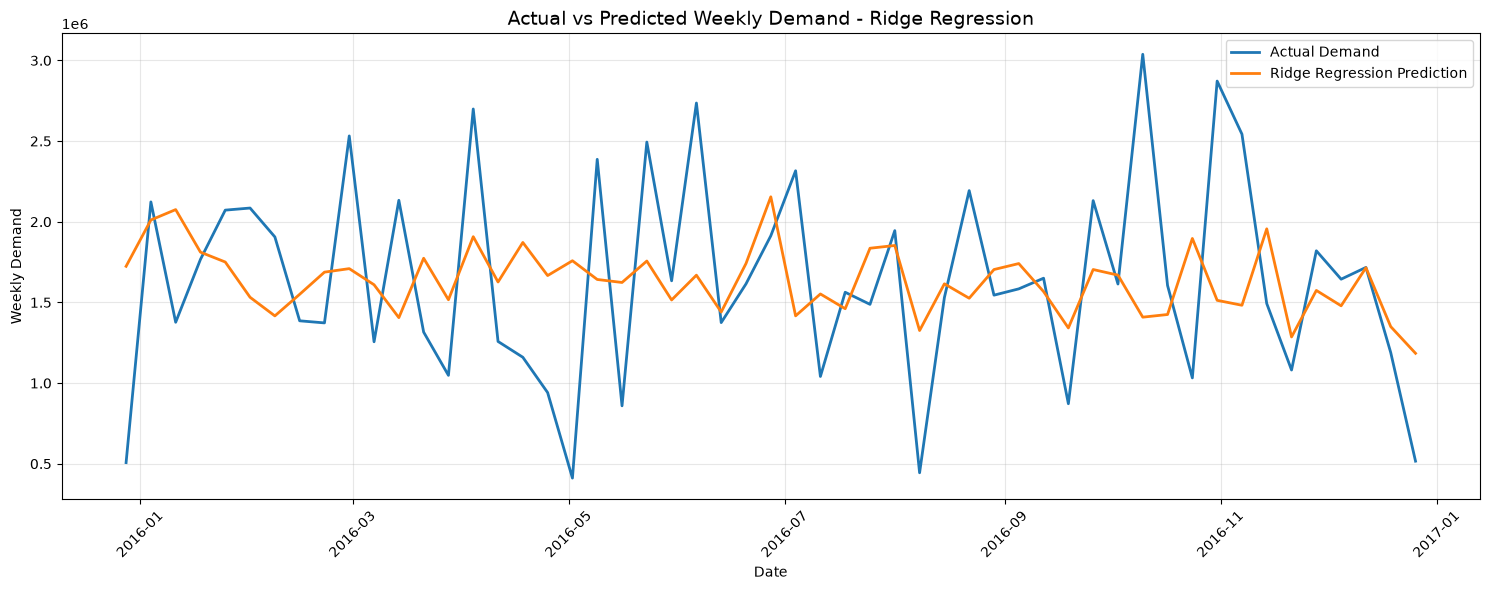

In [129]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label='Actual Demand',
    linewidth=2
)

plt.plot(
    y_test.index,
    ridge_test_predictions,
    label='Ridge Regression Prediction',
    linewidth=2
)

plt.title(
    'Actual vs Predicted Weekly Demand - Ridge Regression',
    fontsize=14
)

plt.xlabel('Date')
plt.ylabel('Weekly Demand')

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [130]:
from sklearn.metrics import mean_absolute_percentage_error, r2_score

# Calculate additional test metrics

ridge_mape = mean_absolute_percentage_error(
    y_test, ridge_test_predictions
) * 100

ridge_r2 = r2_score(
    y_test, ridge_test_predictions
)

print("Ridge Regression - Test Performance")
print("-----------------------------------")
print("MAE:", round(best_ridge_mae, 2))
print("RMSE:", round(
    np.sqrt(mean_squared_error(y_test, ridge_test_predictions)), 2
))
print("MAPE:", round(ridge_mape, 2), "%")
print("R2 Score:", round(ridge_r2, 4))

Ridge Regression - Test Performance
-----------------------------------
MAE: 591528.09
RMSE: 631992.24
MAPE: 42.18 %
R2 Score: -0.0274


In [131]:
# Calculate all metrics using TEST data only

final_mae = mean_absolute_error(
    y_test, ridge_test_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_test_predictions)
)

final_mape = mean_absolute_percentage_error(
    y_test, ridge_test_predictions
) * 100

final_r2 = r2_score(
    y_test, ridge_test_predictions
)

print("RIDGE REGRESSION - FINAL TEST RESULTS")
print("-------------------------------------")
print("MAE:", round(final_mae, 2))
print("RMSE:", round(final_rmse, 2))
print("MAPE:", round(final_mape, 2), "%")
print("R2 Score:", round(final_r2, 4))

RIDGE REGRESSION - FINAL TEST RESULTS
-------------------------------------
MAE: 499931.45
RMSE: 631992.24
MAPE: 42.18 %
R2 Score: -0.0274


In [132]:
# Create a prediction error analysis table

error_analysis = pd.DataFrame(index=y_test.index)

error_analysis['Actual_Demand'] = y_test
error_analysis['Predicted_Demand'] = ridge_test_predictions

error_analysis['Error'] = (
    error_analysis['Actual_Demand'] -
    error_analysis['Predicted_Demand']
)

error_analysis['Absolute_Error'] = (
    error_analysis['Error'].abs()
)

error_analysis['Percentage_Error'] = (
    error_analysis['Absolute_Error'] /
    error_analysis['Actual_Demand'].abs()
) * 100

# Display the 10 largest prediction errors

largest_errors = error_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
).head(10)

display(largest_errors.round(2))

,Actual_Demand,Predicted_Demand,Error,Absolute_Error,Percentage_Error
Date,,,,,
2016-10-10,3038000.0,1408617.35,1629382.65,1629382.65,53.63
2016-10-31,2872000.0,1512983.19,1359016.81,1359016.81,47.32
2016-05-02,411000.0,1758317.48,-1347317.48,1347317.48,327.81
2015-12-28,507000.0,1723858.06,-1216858.06,1216858.06,240.01
2016-06-06,2736000.0,1668863.42,1067136.58,1067136.58,39.00
2016-11-07,2543000.0,1482397.54,1060602.46,1060602.46,41.71
2016-07-04,2316000.0,1416699.27,899300.73,899300.73,38.83
2016-08-08,444000.0,1325661.86,-881661.86,881661.86,198.57
2016-10-24,1032000.0,1896540.94,-864540.94,864540.94,83.77


In [133]:
# Divide actual demand into four groups

error_analysis['Demand_Group'] = pd.qcut(
    error_analysis['Actual_Demand'],
    q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

# Calculate performance for each group

demand_error_summary = error_analysis.groupby(
    'Demand_Group',
    observed=False
).agg(
    Number_of_Weeks=('Actual_Demand', 'count'),
    Average_Actual=('Actual_Demand', 'mean'),
    Average_Predicted=('Predicted_Demand', 'mean'),
    MAE=('Absolute_Error', 'mean'),
    MAPE=('Percentage_Error', 'mean')
).reset_index()

display(demand_error_summary.round(2))





,Demand_Group,Number_of_Weeks,Average_Actual,Average_Predicted,MAE,MAPE
0,Low,14,882642.86,1550478.62,667835.77,101.11
1,Medium-Low,13,1453307.69,1684008.19,274080.38,19.40
2,Medium-High,13,1798615.38,1675292.97,195245.51,10.37
3,High,13,2476692.31,1627043.88,849648.43,33.30


In [134]:
# Create rolling features using only previous weeks

feature_data['Rolling_Mean_4'] = (
    feature_data['Demand']
    .shift(1)
    .rolling(window=4)
    .mean()
)

feature_data['Rolling_Mean_8'] = (
    feature_data['Demand']
    .shift(1)
    .rolling(window=8)
    .mean()
)

feature_data['Rolling_Std_4'] = (
    feature_data['Demand']
    .shift(1)
    .rolling(window=4)
    .std()
)

print("Updated Dataset Shape:", feature_data.shape)

print("\nNew Features:")
display(
    feature_data[
        ['Demand', 'Rolling_Mean_4', 'Rolling_Mean_8', 'Rolling_Std_4']
    ].tail(10)
)

print("\nMissing Values:")
display(feature_data.isnull().sum())

Updated Dataset Shape: (261, 13)

New Features:


,Demand,Rolling_Mean_4,Rolling_Mean_8,Rolling_Std_4
Date,,,,
2016-10-24,1032000.0,2097000.0,1754875.0,673792.747562
2016-10-31,2872000.0,1822250.0,1690750.0,855006.578922
2016-11-07,2543000.0,2136750.0,1851750.0,975717.641875
2016-11-14,1493000.0,2013000.0,1963375.0,846090.223715
2016-11-21,1081000.0,1985000.0,2041000.0,865718.583991
2016-11-28,1820000.0,1997250.0,1909750.0,847901.871288
2016-12-05,1644000.0,1734250.0,1935500.0,618160.375631
2016-12-12,1717000.0,1509500.0,1761250.0,315375.437640
2016-12-19,1189000.0,1565500.0,1775250.0,330970.794281



Missing Values:


Demand             0
Month              0
Quarter            0
WeekOfYear         0
Year               0
Lag_1              1
Lag_2              2
Lag_4              4
Lag_8              8
Lag_52            52
Rolling_Mean_4     4
Rolling_Mean_8     8
Rolling_Std_4      4
dtype: int64

In [135]:
# Remove rows with unavailable historical features

feature_data_clean = feature_data.dropna().copy()

print("Updated Dataset Shape:", feature_data_clean.shape)

print("\nMissing Values:")
display(feature_data_clean.isnull().sum())

print("\nDate Range:")
print(feature_data_clean.index.min(), "to", feature_data_clean.index.max())

Updated Dataset Shape: (209, 13)

Missing Values:


Demand            0
Month             0
Quarter           0
WeekOfYear        0
Year              0
Lag_1             0
Lag_2             0
Lag_4             0
Lag_8             0
Lag_52            0
Rolling_Mean_4    0
Rolling_Mean_8    0
Rolling_Std_4     0
dtype: int64


Date Range:
2012-12-31 00:00:00 to 2016-12-26 00:00:00


In [136]:
# Split using the original date boundaries

ml_train = feature_data_clean.loc[
    feature_data_clean.index <= train_inner.index[-1]
].copy()

ml_validation = feature_data_clean.loc[
    (feature_data_clean.index > train_inner.index[-1]) &
    (feature_data_clean.index <= validation.index[-1])
].copy()

ml_test = feature_data_clean.loc[
    feature_data_clean.index > validation.index[-1]
].copy()

# Separate features and target

X_train = ml_train.drop(columns=['Demand'])
y_train = ml_train['Demand']

X_validation = ml_validation.drop(columns=['Demand'])
y_validation = ml_validation['Demand']

X_test = ml_test.drop(columns=['Demand'])
y_test = ml_test['Demand']

# Display results

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nFeatures:")
print(X_train.columns.tolist())

Training: (114, 12) (114,)
Validation: (42, 12) (42,)
Testing: (53, 12) (53,)

Features:
['Month', 'Quarter', 'WeekOfYear', 'Year', 'Lag_1', 'Lag_2', 'Lag_4', 'Lag_8', 'Lag_52', 'Rolling_Mean_4', 'Rolling_Mean_8', 'Rolling_Std_4']


In [137]:
# Train Ridge Regression with rolling features

ridge_rolling_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=5)
)

ridge_rolling_model.fit(X_train, y_train)

# Validation predictions

rolling_predictions = ridge_rolling_model.predict(X_validation)

# Calculate validation metrics

rolling_mae = mean_absolute_error(
    y_validation, rolling_predictions
)

rolling_rmse = np.sqrt(
    mean_squared_error(y_validation, rolling_predictions)
)

print("Ridge Regression with Rolling Features")
print("---------------------------------------")
print("Validation MAE:", round(rolling_mae, 2))
print("Validation RMSE:", round(rolling_rmse, 2))

print("\nPrevious Ridge Model (9 Features)")
print("Validation MAE:", 591528.09)
print("Validation RMSE:", 722658.06)

Ridge Regression with Rolling Features
---------------------------------------
Validation MAE: 579265.09
Validation RMSE: 716243.09

Previous Ridge Model (9 Features)
Validation MAE: 591528.09
Validation RMSE: 722658.06


In [138]:
alpha_values = [1, 5, 10, 15, 20, 30, 50, 100]

rolling_ridge_results = []

for alpha in alpha_values:

    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=alpha)
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_validation)

    mae = mean_absolute_error(y_validation, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_validation, predictions)
    )

    rolling_ridge_results.append({
        'Alpha': alpha,
        'MAE': mae,
        'RMSE': rmse
    })

rolling_ridge_results = pd.DataFrame(rolling_ridge_results)

display(
    rolling_ridge_results.sort_values('MAE').round(2)
)

,Alpha,MAE,RMSE
1,5,579265.09,716243.09
2,10,579568.15,710829.63
3,15,580344.53,708041.37
0,1,580461.72,726628.21
4,20,581263.96,706534.99
5,30,583166.65,705517.72
6,50,586613.39,706871.07
7,100,599376.68,714283.67


In [139]:
# Final candidate: Ridge Regression with rolling features

best_rolling_ridge = make_pipeline(
    StandardScaler(),
    Ridge(alpha=5)
)

best_rolling_ridge.fit(X_train, y_train)

# Validation predictions
best_rolling_predictions = best_rolling_ridge.predict(X_validation)

# Evaluation
best_rolling_mae = mean_absolute_error(
    y_validation, best_rolling_predictions
)

best_rolling_rmse = np.sqrt(
    mean_squared_error(y_validation, best_rolling_predictions)
)

print("Updated Ridge Model")
print("-------------------")
print("Features:", X_train.shape[1])
print("Alpha: 5")
print("Validation MAE:", round(best_rolling_mae, 2))
print("Validation RMSE:", round(best_rolling_rmse, 2))

Updated Ridge Model
-------------------
Features: 12
Alpha: 5
Validation MAE: 579265.09
Validation RMSE: 716243.09


In [140]:
# Predict test demand using the updated Ridge model

rolling_test_predictions = best_rolling_ridge.predict(X_test)

# Calculate test metrics

rolling_test_mae = mean_absolute_error(
    y_test, rolling_test_predictions
)

rolling_test_rmse = np.sqrt(
    mean_squared_error(y_test, rolling_test_predictions)
)

rolling_test_mape = mean_absolute_percentage_error(
    y_test, rolling_test_predictions
) * 100

rolling_test_r2 = r2_score(
    y_test, rolling_test_predictions
)

print("UPDATED RIDGE MODEL - TEST RESULTS")
print("----------------------------------")
print("MAE:", round(rolling_test_mae, 2))
print("RMSE:", round(rolling_test_rmse, 2))
print("MAPE:", round(rolling_test_mape, 2), "%")
print("R2 Score:", round(rolling_test_r2, 4))

print("\nPrevious Ridge Model - Test Results")
print("MAE:", 499931.45)
print("RMSE:", 631992.24)

UPDATED RIDGE MODEL - TEST RESULTS
----------------------------------
MAE: 520559.03
RMSE: 644728.84
MAPE: 45.28 %
R2 Score: -0.0693

Previous Ridge Model - Test Results
MAE: 499931.45
RMSE: 631992.24


In [141]:
ridge_comparison = pd.DataFrame({
    'Model': [
        'Ridge - Original 9 Features',
        'Ridge - Rolling Features',
        'Ridge - Rolling Features (Alpha 30)'
    ],
    'Validation_MAE': [
        591528.09,
        579265.09,
        583166.65
    ],
    'Test_MAE': [
        499931.45,
        520559.03,
        np.nan
    ],
    'Test_RMSE': [
        631992.24,
        644728.84,
        np.nan
    ]
})

display(ridge_comparison.round(2))

,Model,Validation_MAE,Test_MAE,Test_RMSE
0,Ridge - Original 9 Features,591528.09,499931.45,631992.24
1,Ridge - Rolling Features,579265.09,520559.03,644728.84
2,Ridge - Rolling Features (Alpha 30),583166.65,NaN,NaN


In [142]:
# One-week-ahead Naive Forecast
one_step_naive_predictions = ml_test['Lag_1'].values

naive_mae = mean_absolute_error(y_test, one_step_naive_predictions)
naive_rmse = np.sqrt(mean_squared_error(y_test, one_step_naive_predictions))
naive_mape = mean_absolute_percentage_error(y_test, one_step_naive_predictions) * 100
naive_r2 = r2_score(y_test, one_step_naive_predictions)

print("ONE-STEP-AHEAD NAIVE BASELINE")
print("-----------------------------")
print("MAE:", round(naive_mae, 2))
print("RMSE:", round(naive_rmse, 2))
print("MAPE:", round(naive_mape, 2), "%")
print("R2 Score:", round(naive_r2, 4))

ONE-STEP-AHEAD NAIVE BASELINE
-----------------------------
MAE: 753471.7
RMSE: 929584.77
MAPE: 54.88 %
R2 Score: -1.2229


In [143]:
# One-week-ahead 4-week moving average
ma4_predictions = ml_test[
    ['Lag_1', 'Lag_2', 'Lag_4']
].copy()

# Calculate using the actual previous 4 weeks
ma4_predictions['Lag_3'] = feature_data_clean.loc[
    ml_test.index, 'Demand'
].shift(0).values  # Temporary alignment check

# Use the four previous actual demand values
ma4_predictions = feature_data_clean['Demand'].shift(1).rolling(4).mean().loc[ml_test.index]

ma4_mae = mean_absolute_error(y_test, ma4_predictions)
ma4_rmse = np.sqrt(mean_squared_error(y_test, ma4_predictions))
ma4_mape = mean_absolute_percentage_error(y_test, ma4_predictions) * 100
ma4_r2 = r2_score(y_test, ma4_predictions)

print("ONE-STEP-AHEAD 4-WEEK MOVING AVERAGE")
print("------------------------------------")
print("MAE:", round(ma4_mae, 2))
print("RMSE:", round(ma4_rmse, 2))
print("MAPE:", round(ma4_mape, 2), "%")
print("R2 Score:", round(ma4_r2, 4))

ONE-STEP-AHEAD 4-WEEK MOVING AVERAGE
------------------------------------
MAE: 572518.87
RMSE: 693385.54
MAPE: 47.89 %
R2 Score: -0.2368


In [144]:
final_baseline_comparison = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        '4-Week Moving Average',
        'Ridge Regression (9 Features)'
    ],
    'MAE': [
        753471.70,
        572518.87,
        499931.45
    ],
    'RMSE': [
        929584.77,
        693385.54,
        631992.24
    ],
    'MAPE (%)': [
        54.88,
        47.89,
        42.18
    ],
    'R2 Score': [
        -1.2229,
        -0.2368,
        -0.0274
    ]
})

display(final_baseline_comparison)

,Model,MAE,RMSE,MAPE (%),R2 Score
0,Naive Forecast,753471.70,929584.77,54.88,-1.2229
1,4-Week Moving Average,572518.87,693385.54,47.89,-0.2368
2,Ridge Regression (9 Features),499931.45,631992.24,42.18,-0.0274


In [145]:
# Create a prediction analysis DataFrame
ridge_analysis = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': ridge_test_predictions
}, index=y_test.index)

ridge_analysis['Error'] = (
    ridge_analysis['Actual'] - ridge_analysis['Predicted']
)

ridge_analysis['Absolute_Error'] = ridge_analysis['Error'].abs()

print("RIDGE PREDICTION ERROR ANALYSIS")
print("--------------------------------")
print("Average Actual Demand:",
      round(ridge_analysis['Actual'].mean(), 2))

print("Average Predicted Demand:",
      round(ridge_analysis['Predicted'].mean(), 2))

print("Average Error:",
      round(ridge_analysis['Error'].mean(), 2))

print("Maximum Overprediction:",
      round(ridge_analysis['Error'].min(), 2))

print("Maximum Underprediction:",
      round(ridge_analysis['Error'].max(), 2))

print("\nLargest 5 Prediction Errors:")
display(
    ridge_analysis
    .sort_values('Absolute_Error', ascending=False)
    .head(5)
)

RIDGE PREDICTION ERROR ANALYSIS
--------------------------------
Average Actual Demand: 1638283.02
Average Predicted Demand: 1632626.15
Average Error: 5656.86
Maximum Overprediction: -1347317.48
Maximum Underprediction: 1629382.65

Largest 5 Prediction Errors:


,Actual,Predicted,Error,Absolute_Error
Date,,,,
2016-10-10,3038000.0,1.408617e+06,1.629383e+06,1.629383e+06
2016-10-31,2872000.0,1.512983e+06,1.359017e+06,1.359017e+06
2016-05-02,411000.0,1.758317e+06,-1.347317e+06,1.347317e+06
2015-12-28,507000.0,1.723858e+06,-1.216858e+06,1.216858e+06
2016-06-06,2736000.0,1.668863e+06,1.067137e+06,1.067137e+06


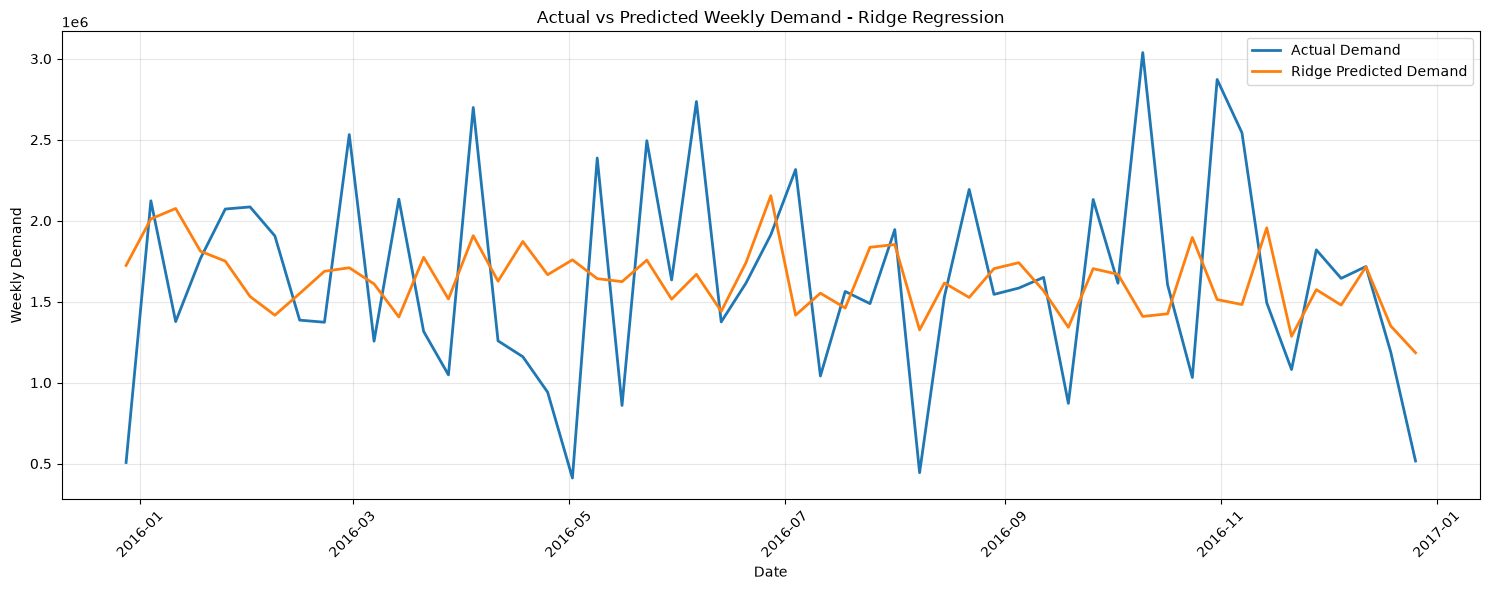

In [146]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(
    ridge_analysis.index,
    ridge_analysis['Actual'],
    label='Actual Demand',
    linewidth=2
)

plt.plot(
    ridge_analysis.index,
    ridge_analysis['Predicted'],
    label='Ridge Predicted Demand',
    linewidth=2
)

plt.title('Actual vs Predicted Weekly Demand - Ridge Regression')
plt.xlabel('Date')
plt.ylabel('Weekly Demand')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [147]:
from sklearn.ensemble import HistGradientBoostingRegressor

print("HistGradientBoostingRegressor imported successfully!")

HistGradientBoostingRegressor imported successfully!


In [148]:
hist_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=10,
    l2_regularization=1,
    random_state=42
)

# Train using training data only
hist_model.fit(X_train, y_train)

# Predict validation demand
hist_validation_predictions = hist_model.predict(X_validation)

# Evaluate validation performance
hist_val_mae = mean_absolute_error(
    y_validation, hist_validation_predictions
)

hist_val_rmse = np.sqrt(
    mean_squared_error(y_validation, hist_validation_predictions)
)

print("HISTGRADIENTBOOSTING - VALIDATION RESULTS")
print("-----------------------------------------")
print("MAE:", round(hist_val_mae, 2))
print("RMSE:", round(hist_val_rmse, 2))

HISTGRADIENTBOOSTING - VALIDATION RESULTS
-----------------------------------------
MAE: 634279.93
RMSE: 781614.41


In [149]:
hist_results = []

for leaves in [5, 10, 15, 20]:
    for learning_rate in [0.03, 0.05, 0.1]:
        model = HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=learning_rate,
            max_leaf_nodes=leaves,
            l2_regularization=1,
            random_state=42
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_validation)

        mae = mean_absolute_error(y_validation, predictions)
        rmse = np.sqrt(mean_squared_error(y_validation, predictions))

        hist_results.append({
            'Max_Leaf_Nodes': leaves,
            'Learning_Rate': learning_rate,
            'Validation_MAE': mae,
            'Validation_RMSE': rmse
        })

hist_tuning_results = pd.DataFrame(hist_results)

hist_tuning_results = hist_tuning_results.sort_values(
    'Validation_MAE'
).reset_index(drop=True)

display(hist_tuning_results.round(2))

print("Best validation MAE:",
      round(hist_tuning_results.iloc[0]['Validation_MAE'], 2))

,Max_Leaf_Nodes,Learning_Rate,Validation_MAE,Validation_RMSE
0,5,0.03,605158.16,755018.86
1,10,0.03,605158.16,755018.86
2,15,0.03,605158.16,755018.86
3,20,0.03,605158.16,755018.86
4,15,0.05,634279.93,781614.41
5,10,0.05,634279.93,781614.41
6,20,0.05,634279.93,781614.41
7,5,0.05,634279.93,781614.41
8,10,0.10,661867.53,807070.14
9,5,0.10,661867.53,807070.14


Best validation MAE: 605158.16


In [150]:
display(hist_tuning_results.head(5).round(2))

,Max_Leaf_Nodes,Learning_Rate,Validation_MAE,Validation_RMSE
0,5,0.03,605158.16,755018.86
1,10,0.03,605158.16,755018.86
2,15,0.03,605158.16,755018.86
3,20,0.03,605158.16,755018.86
4,15,0.05,634279.93,781614.41


In [151]:
display(
    hist_tuning_results[
        ['Max_Leaf_Nodes', 'Learning_Rate',
         'Validation_MAE', 'Validation_RMSE']
    ].round(2).to_string(index=False)
)

' Max_Leaf_Nodes  Learning_Rate  Validation_MAE  Validation_RMSE\n              5           0.03       605158.16        755018.86\n             10           0.03       605158.16        755018.86\n             15           0.03       605158.16        755018.86\n             20           0.03       605158.16        755018.86\n             15           0.05       634279.93        781614.41\n             10           0.05       634279.93        781614.41\n             20           0.05       634279.93        781614.41\n              5           0.05       634279.93        781614.41\n             10           0.10       661867.53        807070.14\n              5           0.10       661867.53        807070.14\n             15           0.10       661867.53        807070.14\n             20           0.10       661867.53        807070.14'

In [152]:
from sklearn.ensemble import RandomForestRegressor

print("Random Forest imported successfully!")

Random Forest imported successfully!


In [153]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict validation data
rf_validation_predictions = rf_model.predict(X_validation)

# Evaluate
rf_val_mae = mean_absolute_error(
    y_validation, rf_validation_predictions
)

rf_val_rmse = np.sqrt(
    mean_squared_error(y_validation, rf_validation_predictions)
)

print("RANDOM FOREST - VALIDATION RESULTS")
print("----------------------------------")
print("MAE:", round(rf_val_mae, 2))
print("RMSE:", round(rf_val_rmse, 2))

RANDOM FOREST - VALIDATION RESULTS
----------------------------------
MAE: 601897.98
RMSE: 714978.1


In [154]:
rf_results = []

for depth in [3, 5, 8, None]:
    for leaf in [2, 5, 10]:

        model = RandomForestRegressor(
            n_estimators=200,
            max_depth=depth,
            min_samples_split=10,
            min_samples_leaf=leaf,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_validation)

        mae = mean_absolute_error(y_validation, predictions)
        rmse = np.sqrt(mean_squared_error(y_validation, predictions))

        rf_results.append({
            'Max_Depth': depth,
            'Min_Samples_Leaf': leaf,
            'Validation_MAE': mae,
            'Validation_RMSE': rmse
        })

rf_tuning_results = pd.DataFrame(rf_results)

rf_tuning_results = rf_tuning_results.sort_values(
    'Validation_MAE'
).reset_index(drop=True)

display(rf_tuning_results.round(2))

,Max_Depth,Min_Samples_Leaf,Validation_MAE,Validation_RMSE
0,8.0,2,599560.93,721525.93
1,NaN,2,600641.05,722660.68
2,NaN,5,601213.16,715144.36
3,8.0,5,601264.28,715173.64
4,5.0,5,601897.98,714978.10
5,3.0,5,602568.16,714191.72
6,5.0,10,602800.53,716576.97
7,NaN,10,602901.19,716686.28
8,8.0,10,602901.19,716686.28
9,3.0,10,604208.14,716517.72


In [155]:
best_rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

best_rf_model.fit(X_train, y_train)

best_rf_validation_predictions = best_rf_model.predict(X_validation)

print("SELECTED RANDOM FOREST MODEL")
print("----------------------------")
print("Validation MAE:",
      round(mean_absolute_error(
          y_validation, best_rf_validation_predictions
      ), 2))

print("Validation RMSE:",
      round(np.sqrt(mean_squared_error(
          y_validation, best_rf_validation_predictions
      )), 2))

SELECTED RANDOM FOREST MODEL
----------------------------
Validation MAE: 599560.93
Validation RMSE: 721525.93


In [156]:
rf_test_predictions = best_rf_model.predict(X_test)

rf_test_mae = mean_absolute_error(y_test, rf_test_predictions)
rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_test_predictions)
)
rf_test_mape = mean_absolute_percentage_error(
    y_test, rf_test_predictions
) * 100
rf_test_r2 = r2_score(y_test, rf_test_predictions)

print("RANDOM FOREST - TEST RESULTS")
print("----------------------------")
print("MAE:", round(rf_test_mae, 2))
print("RMSE:", round(rf_test_rmse, 2))
print("MAPE:", round(rf_test_mape, 2), "%")
print("R2 Score:", round(rf_test_r2, 4))

RANDOM FOREST - TEST RESULTS
----------------------------
MAE: 664921.09
RMSE: 780968.88
MAPE: 64.23 %
R2 Score: -0.5689


In [157]:
model_final_comparison = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        '4-Week Moving Average',
        'Ridge Regression',
        'Ridge with Rolling Features',
        'Random Forest',
    ],
    'MAE': [
        753471.70,
        572518.87,
        499931.45,
        520559.03,
        rf_test_mae
    ],
    'RMSE': [
        929584.77,
        693385.54,
        631992.24,
        644728.84,
        rf_test_rmse
    ],
    'MAPE (%)': [
        54.88,
        47.89,
        42.18,
        45.28,
        rf_test_mape
    ],
    'R2 Score': [
        -1.2229,
        -0.2368,
        -0.0274,
        -0.0693,
        rf_test_r2
    ]
})

display(
    model_final_comparison.sort_values('MAE').reset_index(drop=True).round(2)
)

,Model,MAE,RMSE,MAPE (%),R2 Score
0,Ridge Regression,499931.45,631992.24,42.18,-0.03
1,Ridge with Rolling Features,520559.03,644728.84,45.28,-0.07
2,4-Week Moving Average,572518.87,693385.54,47.89,-0.24
3,Random Forest,664921.09,780968.88,64.23,-0.57
4,Naive Forecast,753471.70,929584.77,54.88,-1.22


In [158]:
from sklearn.model_selection import TimeSeriesSplit

# Combine training and validation data
X_development = pd.concat([X_train, X_validation])
y_development = pd.concat([y_train, y_validation])

# Create 3 chronological validation folds
tscv = TimeSeriesSplit(n_splits=3)

print("WALK-FORWARD VALIDATION SETUP")
print("--------------------------------")
print("Total development observations:", len(X_development))
print("Number of folds:", tscv.get_n_splits())

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development), start=1
):
    print(f"\nFold {fold}")
    print("Training observations:", len(train_idx))
    print("Validation observations:", len(val_idx))
    print("Training period:",
          X_development.index[train_idx[0]].date(),
          "to",
          X_development.index[train_idx[-1]].date())
    print("Validation period:",
          X_development.index[val_idx[0]].date(),
          "to",
          X_development.index[val_idx[-1]].date())

WALK-FORWARD VALIDATION SETUP
--------------------------------
Total development observations: 156
Number of folds: 3

Fold 1
Training observations: 39
Validation observations: 39
Training period: 2012-12-31 to 2013-09-23
Validation period: 2013-09-30 to 2014-06-23

Fold 2
Training observations: 78
Validation observations: 39
Training period: 2012-12-31 to 2014-06-23
Validation period: 2014-06-30 to 2015-03-23

Fold 3
Training observations: 117
Validation observations: 39
Training period: 2012-12-31 to 2015-03-23
Validation period: 2015-03-30 to 2015-12-21


In [159]:
ridge_wf_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development), start=1
):
    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    y_fold_train = y_development.iloc[train_idx]
    y_fold_val = y_development.iloc[val_idx]

    # Create and train Ridge model
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=5)
    )

    model.fit(X_fold_train, y_fold_train)

    # Predict validation period
    predictions = model.predict(X_fold_val)

    # Calculate errors
    mae = mean_absolute_error(y_fold_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_fold_val, predictions))

    ridge_wf_results.append({
        'Fold': fold,
        'Training_Weeks': len(train_idx),
        'Validation_Weeks': len(val_idx),
        'MAE': mae,
        'RMSE': rmse
    })

ridge_wf_df = pd.DataFrame(ridge_wf_results)

display(ridge_wf_df.round(2))

print("AVERAGE WALK-FORWARD PERFORMANCE")
print("--------------------------------")
print("Average MAE:", round(ridge_wf_df['MAE'].mean(), 2))
print("Average RMSE:", round(ridge_wf_df['RMSE'].mean(), 2))

,Fold,Training_Weeks,Validation_Weeks,MAE,RMSE
0,1,39,39,790084.74,943243.65
1,2,78,39,530659.72,661196.81
2,3,117,39,573886.49,713699.08


AVERAGE WALK-FORWARD PERFORMANCE
--------------------------------
Average MAE: 631543.65
Average RMSE: 772713.18


In [160]:
naive_wf_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development), start=1
):

    X_fold_val = X_development.iloc[val_idx]
    y_fold_val = y_development.iloc[val_idx]

    # Previous week's actual demand
    predictions = X_fold_val['Lag_1'].values

    mae = mean_absolute_error(y_fold_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_fold_val, predictions))

    naive_wf_results.append({
        'Fold': fold,
        'MAE': mae,
        'RMSE': rmse
    })

naive_wf_df = pd.DataFrame(naive_wf_results)

print("NAIVE WALK-FORWARD RESULTS")
display(naive_wf_df.round(2))

print("\nAVERAGE NAIVE MAE:",
      round(naive_wf_df['MAE'].mean(), 2))

print("AVERAGE NAIVE RMSE:",
      round(naive_wf_df['RMSE'].mean(), 2))

NAIVE WALK-FORWARD RESULTS


,Fold,MAE,RMSE
0,1,875564.10,1093921.72
1,2,769051.28,907408.30
2,3,986974.36,1210760.71



AVERAGE NAIVE MAE: 877196.58
AVERAGE NAIVE RMSE: 1070696.91


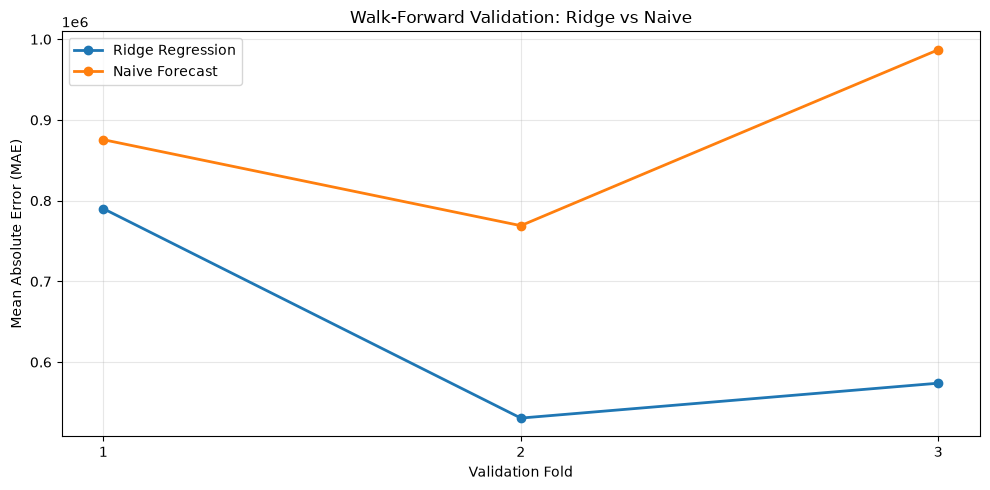

In [161]:
plt.figure(figsize=(10, 5))

plt.plot(
    ridge_wf_df['Fold'],
    ridge_wf_df['MAE'],
    marker='o',
    linewidth=2,
    label='Ridge Regression'
)

plt.plot(
    naive_wf_df['Fold'],
    naive_wf_df['MAE'],
    marker='o',
    linewidth=2,
    label='Naive Forecast'
)

plt.title('Walk-Forward Validation: Ridge vs Naive')
plt.xlabel('Validation Fold')
plt.ylabel('Mean Absolute Error (MAE)')
plt.xticks([1, 2, 3])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [163]:
import scipy

print("SciPy version:", scipy.__version__)

from scipy.optimize import minimize

print("SciPy optimization imported successfully!")


SciPy version: 1.18.1
SciPy optimization imported successfully!


In [164]:
from sklearn.linear_model import LinearRegression

# Prepare four lag features from historical demand
ar_data = pd.DataFrame(index=model_series.index)

ar_data['Demand'] = model_series.values

for lag in range(1, 5):
    ar_data[f'Lag_{lag}'] = ar_data['Demand'].shift(lag)

# Remove rows without four weeks of history
ar_data = ar_data.dropna()

# Chronological development split
ar_development = ar_data.loc[
    X_development.index.min():X_development.index.max()
].copy()

print("AR MODEL DATA")
print("-------------------------")
print("Shape:", ar_development.shape)
print("Features:", list(ar_development.columns))
print("Start date:", ar_development.index.min())
print("End date:", ar_development.index.max())
print("Missing values:", ar_development.isna().sum().sum())

AR MODEL DATA
-------------------------
Shape: (156, 5)
Features: ['Demand', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_4']
Start date: 2012-12-31 00:00:00
End date: 2015-12-21 00:00:00
Missing values: 0


In [165]:
ar_wf_results = []

X_ar = ar_development[['Lag_1', 'Lag_2', 'Lag_3', 'Lag_4']]
y_ar = ar_development['Demand']

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_ar), start=1
):

    X_fold_train = X_ar.iloc[train_idx]
    X_fold_val = X_ar.iloc[val_idx]

    y_fold_train = y_ar.iloc[train_idx]
    y_fold_val = y_ar.iloc[val_idx]

    # Train AR(4) model
    ar_model = LinearRegression()
    ar_model.fit(X_fold_train, y_fold_train)

    # Predict validation period
    predictions = ar_model.predict(X_fold_val)

    mae = mean_absolute_error(y_fold_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_fold_val, predictions))

    ar_wf_results.append({
        'Fold': fold,
        'MAE': mae,
        'RMSE': rmse
    })

ar_wf_df = pd.DataFrame(ar_wf_results)

print("AR(4) WALK-FORWARD RESULTS")
display(ar_wf_df.round(2))

print("\nAVERAGE AR(4) MAE:",
      round(ar_wf_df['MAE'].mean(), 2))

print("AVERAGE AR(4) RMSE:",
      round(ar_wf_df['RMSE'].mean(), 2))

AR(4) WALK-FORWARD RESULTS


,Fold,MAE,RMSE
0,1,560164.56,718334.58
1,2,531835.53,668856.26
2,3,614910.86,764722.53



AVERAGE AR(4) MAE: 568970.32
AVERAGE AR(4) RMSE: 717304.46


In [166]:
ar_lag_results = []

for lag_count in [2, 4, 6, 8]:

    lag_data = pd.DataFrame(index=model_series.index)
    lag_data['Demand'] = model_series

    for lag in range(1, lag_count + 1):
        lag_data[f'Lag_{lag}'] = lag_data['Demand'].shift(lag)

    lag_data = lag_data.dropna()

    # Keep the same development period
    lag_data = lag_data.loc[X_development.index.min():X_development.index.max()]

    X_lag = lag_data.drop(columns='Demand')
    y_lag = lag_data['Demand']

    fold_maes = []
    fold_rmses = []

    for train_idx, val_idx in tscv.split(X_lag):

        X_train_fold = X_lag.iloc[train_idx]
        X_val_fold = X_lag.iloc[val_idx]

        y_train_fold = y_lag.iloc[train_idx]
        y_val_fold = y_lag.iloc[val_idx]

        model = LinearRegression()
        model.fit(X_train_fold, y_train_fold)

        predictions = model.predict(X_val_fold)

        fold_maes.append(
            mean_absolute_error(y_val_fold, predictions)
        )

        fold_rmses.append(
            np.sqrt(mean_squared_error(y_val_fold, predictions))
        )

    ar_lag_results.append({
        'AR_Lags': lag_count,
        'Average_MAE': np.mean(fold_maes),
        'Average_RMSE': np.mean(fold_rmses)
    })

ar_lag_comparison = pd.DataFrame(ar_lag_results)

display(ar_lag_comparison.round(2))

,AR_Lags,Average_MAE,Average_RMSE
0,2,585763.54,722386.98
1,4,568970.32,717304.46
2,6,575897.16,723019.85
3,8,577377.44,723980.04


In [167]:
walkforward_comparison = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        'Ridge Regression',
        'AR(2)',
        'AR(4)',
        'AR(6)',
        'AR(8)'
    ],
    'Average_MAE': [
        naive_wf_df['MAE'].mean(),
        ridge_wf_df['MAE'].mean(),
        585763.54,
        568970.32,
        575897.16,
        577377.44
    ],
    'Average_RMSE': [
        naive_wf_df['RMSE'].mean(),
        ridge_wf_df['RMSE'].mean(),
        722386.98,
        717304.46,
        723019.85,
        723980.04
    ]
})

display(
    walkforward_comparison
    .sort_values('Average_MAE')
    .reset_index(drop=True)
    .round(2)
)

,Model,Average_MAE,Average_RMSE
0,AR(4),568970.32,717304.46
1,AR(6),575897.16,723019.85
2,AR(8),577377.44,723980.04
3,AR(2),585763.54,722386.98
4,Ridge Regression,631543.65,772713.18
5,Naive Forecast,877196.58,1070696.91


In [168]:
ar_regularisation_results = []

for alpha in [0.01, 0.1, 1, 5, 10, 20, 50, 100]:

    fold_maes = []
    fold_rmses = []

    for train_idx, val_idx in tscv.split(X_ar):

        X_fold_train = X_ar.iloc[train_idx]
        X_fold_val = X_ar.iloc[val_idx]

        y_fold_train = y_ar.iloc[train_idx]
        y_fold_val = y_ar.iloc[val_idx]

        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

        fold_rmses.append(
            np.sqrt(mean_squared_error(y_fold_val, predictions))
        )

    ar_regularisation_results.append({
        'Alpha': alpha,
        'Average_MAE': np.mean(fold_maes),
        'Average_RMSE': np.mean(fold_rmses)
    })

ar_regularisation_df = pd.DataFrame(ar_regularisation_results)

display(
    ar_regularisation_df
    .sort_values('Average_MAE')
    .reset_index(drop=True)
    .round(2)
)

,Alpha,Average_MAE,Average_RMSE
0,0.01,568971.28,717304.31
1,0.10,568979.95,717303.02
2,1.00,569083.70,717292.39
3,5.00,569537.50,717286.20
4,10.00,569989.06,717344.58
5,20.00,570662.39,717576.62
6,50.00,573285.98,718498.54
7,100.00,575996.49,719840.63


In [169]:
ar_trend_data = ar_development.copy()

ar_trend_data['Time_Index'] = np.arange(len(ar_trend_data))

X_ar_trend = ar_trend_data[
    ['Lag_1', 'Lag_2', 'Lag_3', 'Lag_4', 'Time_Index']
]

y_ar_trend = ar_trend_data['Demand']

ar_trend_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_ar_trend), start=1
):

    X_fold_train = X_ar_trend.iloc[train_idx]
    X_fold_val = X_ar_trend.iloc[val_idx]

    y_fold_train = y_ar_trend.iloc[train_idx]
    y_fold_val = y_ar_trend.iloc[val_idx]

    model = make_pipeline(
        StandardScaler(),
        LinearRegression()
    )

    model.fit(X_fold_train, y_fold_train)

    predictions = model.predict(X_fold_val)

    ar_trend_results.append({
        'Fold': fold,
        'MAE': mean_absolute_error(y_fold_val, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_fold_val, predictions)
        )
    })

ar_trend_df = pd.DataFrame(ar_trend_results)

display(ar_trend_df.round(2))

print("Average MAE:",
      round(ar_trend_df['MAE'].mean(), 2))

print("Average RMSE:",
      round(ar_trend_df['RMSE'].mean(), 2))

,Fold,MAE,RMSE
0,1,1010932.81,1180612.35
1,2,524517.09,650476.02
2,3,578169.57,738952.07


Average MAE: 704539.82
Average RMSE: 856680.15


In [170]:
seasonal_ar_data = pd.DataFrame(index=model_series.index)

seasonal_ar_data['Demand'] = model_series

for lag in range(1, 5):
    seasonal_ar_data[f'Lag_{lag}'] = (
        seasonal_ar_data['Demand'].shift(lag)
    )

seasonal_ar_data['Lag_52'] = (
    seasonal_ar_data['Demand'].shift(52)
)

seasonal_ar_data = seasonal_ar_data.dropna()

seasonal_ar_data = seasonal_ar_data.loc[
    X_development.index.min():X_development.index.max()
]

print("SEASONAL AR DATA")
print("----------------")
print("Shape:", seasonal_ar_data.shape)
print("Features:", list(seasonal_ar_data.columns))
print("Missing values:", seasonal_ar_data.isna().sum().sum())
print("Start:", seasonal_ar_data.index.min())
print("End:", seasonal_ar_data.index.max())

SEASONAL AR DATA
----------------
Shape: (156, 6)
Features: ['Demand', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_4', 'Lag_52']
Missing values: 0
Start: 2012-12-31 00:00:00
End: 2015-12-21 00:00:00


In [171]:
seasonal_features = [
    'Lag_1', 'Lag_2', 'Lag_3', 'Lag_4', 'Lag_52'
]

X_seasonal = seasonal_ar_data[seasonal_features]
y_seasonal = seasonal_ar_data['Demand']

seasonal_ar_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_seasonal), start=1
):

    X_fold_train = X_seasonal.iloc[train_idx]
    X_fold_val = X_seasonal.iloc[val_idx]

    y_fold_train = y_seasonal.iloc[train_idx]
    y_fold_val = y_seasonal.iloc[val_idx]

    model = LinearRegression()
    model.fit(X_fold_train, y_fold_train)

    predictions = model.predict(X_fold_val)

    seasonal_ar_results.append({
        'Fold': fold,
        'MAE': mean_absolute_error(y_fold_val, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_fold_val, predictions)
        )
    })

seasonal_ar_df = pd.DataFrame(seasonal_ar_results)

display(seasonal_ar_df.round(2))

print("AVERAGE SEASONAL AR MAE:",
      round(seasonal_ar_df['MAE'].mean(), 2))

print("AVERAGE SEASONAL AR RMSE:",
      round(seasonal_ar_df['RMSE'].mean(), 2))

,Fold,MAE,RMSE
0,1,627785.58,762236.92
1,2,550799.57,669001.06
2,3,621252.31,752081.21


AVERAGE SEASONAL AR MAE: 599945.82
AVERAGE SEASONAL AR RMSE: 727773.07


In [172]:
# Prepare AR(4) features for the full time series
ar_test_data = pd.DataFrame(index=model_series.index)
ar_test_data['Demand'] = model_series

for lag in range(1, 5):
    ar_test_data[f'Lag_{lag}'] = model_series.shift(lag)

# Select the same test dates used by our other models
ar_test_data = ar_test_data.loc[ml_test.index]

X_ar_test = ar_test_data[
    ['Lag_1', 'Lag_2', 'Lag_3', 'Lag_4']
]
y_ar_test = ar_test_data['Demand']

# Train AR(4) using development data
ar4_final_model = LinearRegression()
ar4_final_model.fit(X_ar, y_ar)

# Predict test demand
ar4_test_predictions = ar4_final_model.predict(X_ar_test)

# Evaluate
ar4_test_mae = mean_absolute_error(
    y_ar_test, ar4_test_predictions
)

ar4_test_rmse = np.sqrt(
    mean_squared_error(y_ar_test, ar4_test_predictions)
)

ar4_test_mape = np.mean(
    np.abs(
        (y_ar_test.values - ar4_test_predictions)
        / y_ar_test.values
    )
) * 100

ar4_test_r2 = r2_score(
    y_ar_test, ar4_test_predictions
)

print("AR(4) TEST RESULTS")
print("------------------")
print("MAE:", round(ar4_test_mae, 2))
print("RMSE:", round(ar4_test_rmse, 2))
print("MAPE:", round(ar4_test_mape, 2), "%")
print("R2 Score:", round(ar4_test_r2, 4))

AR(4) TEST RESULTS
------------------
MAE: 566391.34
RMSE: 709251.63
MAPE: 58.02 %
R2 Score: -0.294


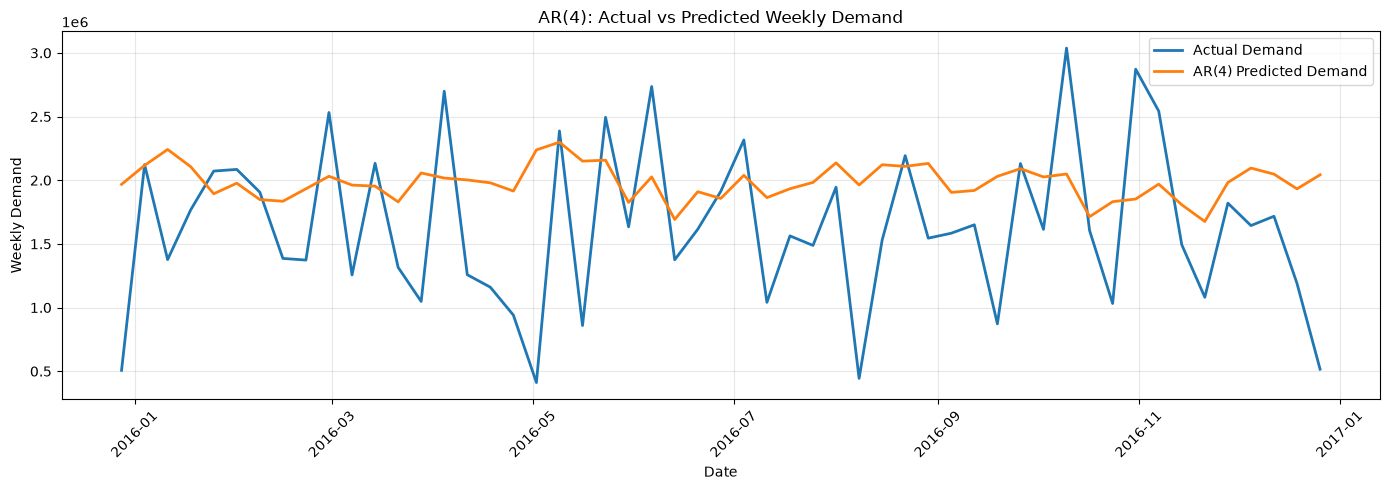

In [173]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    y_ar_test.index,
    y_ar_test.values,
    label='Actual Demand',
    linewidth=2
)

plt.plot(
    y_ar_test.index,
    ar4_test_predictions,
    label='AR(4) Predicted Demand',
    linewidth=2
)

plt.title('AR(4): Actual vs Predicted Weekly Demand')
plt.xlabel('Date')
plt.ylabel('Weekly Demand')
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [174]:
ar4_errors = y_ar_test.values - ar4_test_predictions

print("AR(4) ERROR ANALYSIS")
print("--------------------")

print("Average Error:", round(np.mean(ar4_errors), 2))
print("Underestimated Weeks:", np.sum(ar4_errors > 0))
print("Overestimated Weeks:", np.sum(ar4_errors < 0))
print("Maximum Underestimation:", round(np.max(ar4_errors), 2))
print("Maximum Overestimation:", round(abs(np.min(ar4_errors)), 2))

AR(4) ERROR ANALYSIS
--------------------
Average Error: -344221.02
Underestimated Weeks: 17
Overestimated Weeks: 36
Maximum Underestimation: 1019536.39
Maximum Overestimation: 1827192.34


In [175]:
import importlib.util

if importlib.util.find_spec("xgboost") is not None:
    print("XGBoost is already installed!")
    import xgboost
    print("Version:", xgboost.__version__)
else:
    print("XGBoost is NOT installed.")

XGBoost is already installed!
Version: 3.4.1


In [177]:
from xgboost import XGBRegressor

print("XGBRegressor imported successfully!")

XGBRegressor imported successfully!


In [178]:
xgb_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_development), start=1
):

    X_fold_train = X_development.iloc[train_idx]
    X_fold_val = X_development.iloc[val_idx]

    y_fold_train = y_development.iloc[train_idx]
    y_fold_val = y_development.iloc[val_idx]

    xgb_model = XGBRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=2,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='reg:squarederror',
        random_state=42,
        n_jobs=-1
    )

    xgb_model.fit(X_fold_train, y_fold_train)

    predictions = xgb_model.predict(X_fold_val)

    xgb_results.append({
        'Fold': fold,
        'MAE': mean_absolute_error(y_fold_val, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_fold_val, predictions)
        )
    })

xgb_results_df = pd.DataFrame(xgb_results)

display(xgb_results_df.round(2))

print("AVERAGE XGBOOST MAE:",
      round(xgb_results_df['MAE'].mean(), 2))

print("AVERAGE XGBOOST RMSE:",
      round(xgb_results_df['RMSE'].mean(), 2))

,Fold,MAE,RMSE
0,1,723622.68,858909.72
1,2,508955.71,640064.61
2,3,594577.07,724929.30


AVERAGE XGBOOST MAE: 609051.82
AVERAGE XGBOOST RMSE: 741301.21


In [179]:
xgb_tuning_results = []

for learning_rate in [0.01, 0.03, 0.05]:

    fold_maes = []
    fold_rmses = []

    for train_idx, val_idx in tscv.split(X_development):

        X_fold_train = X_development.iloc[train_idx]
        X_fold_val = X_development.iloc[val_idx]

        y_fold_train = y_development.iloc[train_idx]
        y_fold_val = y_development.iloc[val_idx]

        model = XGBRegressor(
            n_estimators=300,
            learning_rate=learning_rate,
            max_depth=2,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='reg:squarederror',
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

        fold_rmses.append(
            np.sqrt(mean_squared_error(y_fold_val, predictions))
        )

    xgb_tuning_results.append({
        'Learning Rate': learning_rate,
        'Average MAE': np.mean(fold_maes),
        'Average RMSE': np.mean(fold_rmses)
    })

xgb_tuning_df = pd.DataFrame(xgb_tuning_results)

display(xgb_tuning_df.round(2))

,Learning Rate,Average MAE,Average RMSE
0,0.01,596490.23,721463.89
1,0.03,630344.94,769414.72
2,0.05,648041.95,801448.27


In [180]:
xgb_depth_results = []

for depth in [2, 3, 4, 5]:

    fold_maes = []
    fold_rmses = []

    for train_idx, val_idx in tscv.split(X_development):

        X_fold_train = X_development.iloc[train_idx]
        X_fold_val = X_development.iloc[val_idx]

        y_fold_train = y_development.iloc[train_idx]
        y_fold_val = y_development.iloc[val_idx]

        model = XGBRegressor(
            n_estimators=300,
            learning_rate=0.01,
            max_depth=depth,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='reg:squarederror',
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

        fold_rmses.append(
            np.sqrt(mean_squared_error(y_fold_val, predictions))
        )

    xgb_depth_results.append({
        'Max Depth': depth,
        'Average MAE': np.mean(fold_maes),
        'Average RMSE': np.mean(fold_rmses)
    })

xgb_depth_df = pd.DataFrame(xgb_depth_results)

display(xgb_depth_df.round(2))

,Max Depth,Average MAE,Average RMSE
0,2,596490.23,721463.89
1,3,592905.53,722265.82
2,4,589122.40,721526.51
3,5,585433.84,721252.99


In [181]:
xgb_child_results = []

for child_weight in [1, 5, 10]:

    fold_maes = []
    fold_rmses = []

    for train_idx, val_idx in tscv.split(X_development):

        X_fold_train = X_development.iloc[train_idx]
        X_fold_val = X_development.iloc[val_idx]

        y_fold_train = y_development.iloc[train_idx]
        y_fold_val = y_development.iloc[val_idx]

        model = XGBRegressor(
            n_estimators=300,
            learning_rate=0.01,
            max_depth=5,
            min_child_weight=child_weight,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='reg:squarederror',
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

        fold_rmses.append(
            np.sqrt(mean_squared_error(y_fold_val, predictions))
        )

    xgb_child_results.append({
        'Min Child Weight': child_weight,
        'Average MAE': np.mean(fold_maes),
        'Average RMSE': np.mean(fold_rmses)
    })

xgb_child_df = pd.DataFrame(xgb_child_results)

display(xgb_child_df.round(2))

,Min Child Weight,Average MAE,Average RMSE
0,1,596150.11,730891.12
1,5,585433.84,721252.99
2,10,576395.16,705245.78


In [182]:
xgb_subsample_results = []

for sample in [0.6, 0.8, 1.0]:

    fold_maes = []
    fold_rmses = []

    for train_idx, val_idx in tscv.split(X_development):

        X_fold_train = X_development.iloc[train_idx]
        X_fold_val = X_development.iloc[val_idx]

        y_fold_train = y_development.iloc[train_idx]
        y_fold_val = y_development.iloc[val_idx]

        model = XGBRegressor(
            n_estimators=300,
            learning_rate=0.01,
            max_depth=5,
            min_child_weight=10,
            subsample=sample,
            colsample_bytree=0.8,
            objective='reg:squarederror',
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)

        fold_maes.append(
            mean_absolute_error(y_fold_val, predictions)
        )

        fold_rmses.append(
            np.sqrt(mean_squared_error(y_fold_val, predictions))
        )

    xgb_subsample_results.append({
        'Subsample': sample,
        'Average MAE': np.mean(fold_maes),
        'Average RMSE': np.mean(fold_rmses)
    })

xgb_subsample_df = pd.DataFrame(xgb_subsample_results)

display(xgb_subsample_df.round(2))

,Subsample,Average MAE,Average RMSE
0,0.6,577296.79,703688.69
1,0.8,576395.16,705245.78
2,1.0,582688.19,711023.03


In [183]:
final_xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.01,
    max_depth=5,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

final_xgb_model.fit(X_development, y_development)

xgb_test_predictions = final_xgb_model.predict(X_test)

xgb_test_mae = mean_absolute_error(
    y_test, xgb_test_predictions
)

xgb_test_rmse = np.sqrt(
    mean_squared_error(y_test, xgb_test_predictions)
)

xgb_test_mape = np.mean(
    np.abs((y_test.values - xgb_test_predictions) / y_test.values)
) * 100

xgb_test_r2 = r2_score(y_test, xgb_test_predictions)

print("FINAL XGBOOST TEST RESULTS")
print("--------------------------")
print("MAE:", round(xgb_test_mae, 2))
print("RMSE:", round(xgb_test_rmse, 2))
print("MAPE:", round(xgb_test_mape, 2), "%")
print("R2 Score:", round(xgb_test_r2, 4))

FINAL XGBOOST TEST RESULTS
--------------------------
MAE: 610962.36
RMSE: 754161.42
MAPE: 60.1 %
R2 Score: -0.4631


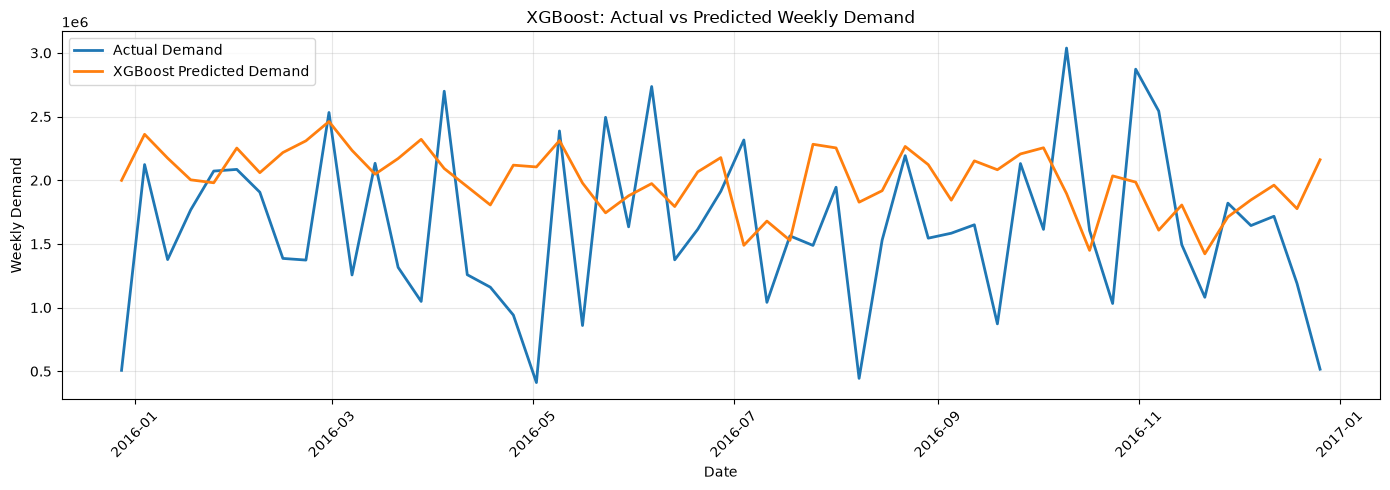

In [184]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index,
    y_test.values,
    label='Actual Demand',
    linewidth=2
)

plt.plot(
    y_test.index,
    xgb_test_predictions,
    label='XGBoost Predicted Demand',
    linewidth=2
)

plt.title('XGBoost: Actual vs Predicted Weekly Demand')
plt.xlabel('Date')
plt.ylabel('Weekly Demand')
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [185]:
xgb_errors = y_test.values - xgb_test_predictions

print("XGBOOST ERROR ANALYSIS")
print("----------------------")

print("Average Error:", round(np.mean(xgb_errors), 2))
print("Underestimated Weeks:", np.sum(xgb_errors > 0))
print("Overestimated Weeks:", np.sum(xgb_errors < 0))
print("Maximum Underestimation:", round(np.max(xgb_errors), 2))
print("Maximum Overestimation:", round(abs(np.min(xgb_errors)), 2))

XGBOOST ERROR ANALYSIS
----------------------
Average Error: -364377.38
Underestimated Weeks: 14
Overestimated Weeks: 39
Maximum Underestimation: 1142842.88
Maximum Overestimation: 1693448.75


,Feature,Importance
10,Rolling_Mean_8,0.1104
8,Lag_52,0.0977
1,Quarter,0.0972
2,WeekOfYear,0.0901
6,Lag_4,0.0866
5,Lag_2,0.0839
0,Month,0.0786
9,Rolling_Mean_4,0.0759
7,Lag_8,0.0736
4,Lag_1,0.0700


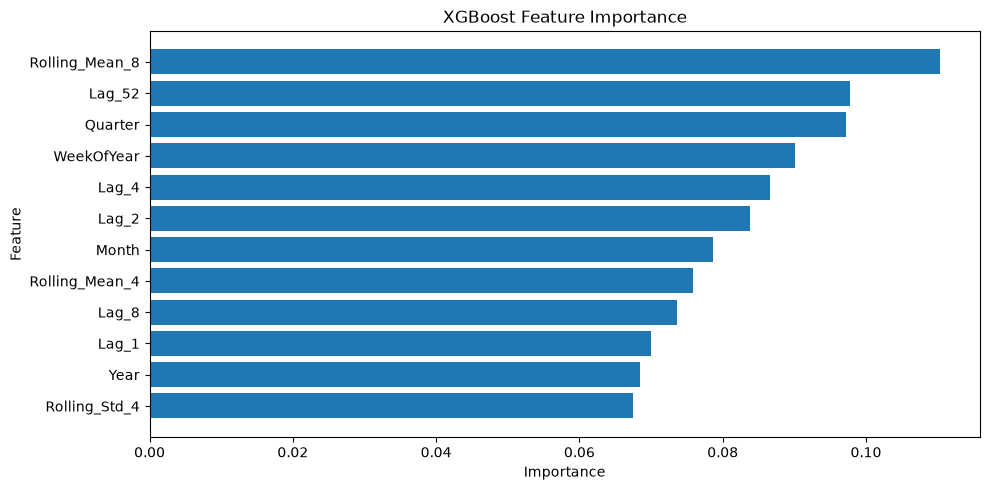

In [186]:
xgb_importance = pd.DataFrame({
    'Feature': X_development.columns,
    'Importance': final_xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by='Importance',
    ascending=False
)

display(xgb_importance.round(4))

plt.figure(figsize=(10, 5))

plt.barh(
    xgb_importance['Feature'],
    xgb_importance['Importance']
)

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [187]:
xgb_importance.to_csv(
    'xgboost_feature_importance.csv',
    index=False
)

print("XGBoost feature importance saved successfully!")

XGBoost feature importance saved successfully!


In [188]:
final_comparison = pd.DataFrame({
    'Model': [
        'Ridge Regression',
        'AR(4)',
        'XGBoost',
        'Random Forest',
        '4-Week Moving Average',
        'Naive Forecast'
    ],
    'MAE': [
        499931.45,
        566391.34,
        610962.36,
        664921.09,
        572518.87,
        753471.70
    ],
    'RMSE': [
        631992.24,
        709251.63,
        754161.42,
        780968.88,
        693385.54,
        929584.77
    ],
    'MAPE': [
        42.18,
        58.02,
        60.10,
        64.23,
        47.89,
        54.88
    ],
    'R2': [
        -0.0274,
        -0.2940,
        -0.4631,
        -0.5689,
        -0.2368,
        -1.2229
    ]
})

final_comparison = final_comparison.sort_values(
    by='MAE'
).reset_index(drop=True)

display(final_comparison.round(2))

,Model,MAE,RMSE,MAPE,R2
0,Ridge Regression,499931.45,631992.24,42.18,-0.03
1,AR(4),566391.34,709251.63,58.02,-0.29
2,4-Week Moving Average,572518.87,693385.54,47.89,-0.24
3,XGBoost,610962.36,754161.42,60.10,-0.46
4,Random Forest,664921.09,780968.88,64.23,-0.57
5,Naive Forecast,753471.70,929584.77,54.88,-1.22


In [189]:
final_comparison.to_csv(
    'final_model_comparison.csv',
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!


In [191]:
average_actual_demand = y_test.mean()
median_actual_demand = y_test.median()

ridge_test_mae = 499931.45

mae_percentage = (
    ridge_test_mae / average_actual_demand
) * 100

print("BUSINESS IMPACT ANALYSIS")
print("-----------------------")
print("Average Weekly Demand:", round(average_actual_demand, 2))
print("Median Weekly Demand:", round(median_actual_demand, 2))
print("Average Prediction Error:", round(ridge_test_mae, 2))
print("MAE as % of Average Demand:", round(mae_percentage, 2), "%")

BUSINESS IMPACT ANALYSIS
-----------------------
Average Weekly Demand: 1638283.02
Median Weekly Demand: 1605000.0
Average Prediction Error: 499931.45
MAE as % of Average Demand: 30.52 %


In [192]:
naive_mae = 753471.70
ridge_mae = 499931.45

mae_improvement = (
    (naive_mae - ridge_mae) / naive_mae
) * 100

print("MODEL IMPROVEMENT")
print("-----------------")
print("Naive Forecast MAE:", round(naive_mae, 2))
print("Ridge Regression MAE:", round(ridge_mae, 2))
print("MAE Improvement:", round(mae_improvement, 2), "%")

MODEL IMPROVEMENT
-----------------
Naive Forecast MAE: 753471.7
Ridge Regression MAE: 499931.45
MAE Improvement: 33.65 %


In [193]:
business_summary = pd.DataFrame({
    'Metric': [
        'Average Weekly Demand',
        'Median Weekly Demand',
        'Ridge Regression MAE',
        'MAE as Percentage of Average Demand',
        'Naive Forecast MAE',
        'Improvement over Naive Forecast'
    ],
    'Value': [
        average_actual_demand,
        median_actual_demand,
        ridge_test_mae,
        mae_percentage,
        naive_mae,
        mae_improvement
    ]
})

business_summary.to_csv(
    'business_impact_summary.csv',
    index=False
)

display(business_summary.round(2))

print("Business impact summary saved successfully!")

,Metric,Value
0,Average Weekly Demand,1638283.02
1,Median Weekly Demand,1605000.00
2,Ridge Regression MAE,499931.45
3,MAE as Percentage of Average Demand,30.52
4,Naive Forecast MAE,753471.70
5,Improvement over Naive Forecast,33.65


Business impact summary saved successfully!


In [194]:
project_findings = """
WEEKLY PRODUCT DEMAND FORECASTING

Dataset: Historical Product Demand
Selected Product: Product_1359
Warehouse: Whse_J
Forecasting Frequency: Weekly

OBJECTIVE:
Forecast weekly product demand to support inventory planning.

BEST TEST-PERIOD MODEL:
Ridge Regression

TEST PERFORMANCE:
MAE: 499931.45
RMSE: 631992.24
MAPE: 42.18%
R2: -0.0274

BUSINESS FINDINGS:
Average weekly demand: 1638283.02
Median weekly demand: 1605000
MAE relative to average demand: 30.52%
Improvement over naive forecast: 33.65%

IMPORTANT LIMITATIONS:
The test period was repeatedly examined during model development.
Three missing weekly observations were interpolated.
The model was evaluated using one-week-ahead predictions.
The negative R2 indicates limited predictive performance.
"""

with open("project_findings.txt", "w") as file:
    file.write(project_findings)

print("Project findings saved successfully!")

Project findings saved successfully!
